# Lesion Segmentation — Mobile-UNet v2 (small-lesion focused revision)

No external backbones, no pretrained weights, no transfer learning — same constraint as before.

## What changed vs the previous notebook, and why

Your best run (`mu_b_tuned`) plateaued at val Dice 0.586 with a growing train/val gap (~0.12
by the end), and nearly half the validation set (195/455 images) has lesions under 5% of the
frame, scoring 0.25–0.47 Dice, while large lesions already score 0.78. Bumping filters
(32→48→64) would make the gap worse, not close it. This revision targets the actual
bottleneck — small-lesion visibility and overfitting — instead of capacity:

| Change | Why | Section |
|---|---|---|
| **Lesion-centered crop training** | At 256px whole-frame letterbox, a 1% lesion is a few dozen pixels. Training-time random crops around the lesion bbox (with a jittered margin) raise the effective resolution exactly for the cases that were failing. | 7 |
| **Weighted / oversampled batches by lesion-size bin** | Small-lesion images are a minority; the loss barely notices them despite Tversky weighting. An `tf.data.Dataset.sample_from_datasets` mixer now samples each size bin at an explicit target frequency every epoch. | 8 |
| **Elastic deformation + cutout on top of existing aug** | Only flip + small affine + color jitter existed before — thin for medical imaging on 1,816 training images. | 9 |
| **Higher weight decay (1e-5 → 5e-5), resolution bump (256 → 320)** | Addresses the overfitting that already exists before adding any capacity. | 2 |
| **Gradient accumulation** | Keeps an OOM-safe physical batch size at the higher resolution while preserving a larger *effective* batch. | 18 |
| **SWA (stochastic weight averaging)** over the last few checkpoints, with a short BN recalibration pass | Val Dice bounces ±0.03 after convergence; averaging late-epoch weights is more stable than one best-epoch snapshot. | 19b |
| **JPEG integrity scan** | "Premature end of JPEG file" fired on nearly every batch. This counts how many files are actually truncated. | 5b |
| **Multi-variant ensemble at inference** | Averages probabilities across whichever `*_final.keras` files exist on disk — free few-point Dice gain. | 25 |

Everything else (COCO loading, mask generation, model architecture, losses, layer-name
registry, threshold calibration, size-breakdown reporting) is unchanged from the previous
notebook so results stay comparable.

Run **one variant per kernel session** (`VARIANT` in Section 2). The ensemble cell at the end
picks up every variant you've trained so far.


In [1]:
# ============================================================
# 1. ENVIRONMENT / GPU
# ============================================================
import os
import sys
import json
import time
import math
import random
import warnings
from pathlib import Path
from collections import Counter

os.environ.setdefault("OPENCV_IO_ENABLE_JASPER", "1")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow.keras import layers, models

warnings.filterwarnings("ignore", category=UserWarning)
try:
    cv2.setLogLevel(0)          # silence "Premature end of JPEG file" (OpenCV 4.x)
except AttributeError:
    try:
        cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_SILENT)
    except Exception:
        pass

print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("Keras      :", tf.keras.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPUs found :", len(gpus))

if not gpus:
    raise RuntimeError("STOP: No GPU visible. Do not start the 50-epoch run on CPU.")

try:
    tf.config.set_visible_devices(gpus[0], "GPU")
except Exception as e:
    print("Device-pin note:", e)

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("Memory-growth note:", e)

print("Using GPU  :", tf.config.get_visible_devices("GPU"))

from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy("mixed_float16")
print("Mixed precision policy:", mixed_precision.global_policy())

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

print("Environment: OK")


Python     : 3.12.13
TensorFlow : 2.20.0
Keras      : 3.13.2
GPUs found : 2
Using GPU  : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy: <DTypePolicy "mixed_float16">
Environment: OK


In [2]:
# ============================================================
# 2. CONFIGURATION
# ============================================================

VARIANT = "mu_b_tuned"
# "mu_a_ablation" | "mu_b_tuned" | "mu_c_wide_aspp" | "mu_d_deepsup"

# base_filters are UNCHANGED on purpose -- the diagnosis was small-lesion
# visibility + overfitting, not underfitting, so capacity stays fixed while
# img_size/aug/sampling/regularization change. img_size goes up (256->320),
# so batch_size drops and grad_accum_steps compensates.
VARIANTS = {
    "mu_a_ablation": {
        "base_filters": 16, "depth": 4, "img_size": 288, "batch_size": 8,
        "grad_accum_steps": 2,
        "residual": False, "gates": False, "cbam": True, "aspp": False,
        "deep_sup": False, "dropout": 0.0, "activation": "relu",
        "lr": 3e-4, "note": "v1 topology, tuned optimizer/loss only",
    },
    "mu_b_tuned": {
        "base_filters": 32, "depth": 4, "img_size": 320, "batch_size": 4,
        "grad_accum_steps": 4,
        "residual": True, "gates": True, "cbam": True, "aspp": False,
        "deep_sup": False, "dropout": 0.15, "activation": "swish",
        "lr": 3e-4, "note": "main tuned Mobile-UNet, effective batch 16 via grad accum",
    },
    "mu_c_wide_aspp": {
        "base_filters": 48, "depth": 4, "img_size": 288, "batch_size": 3,
        "grad_accum_steps": 4,
        "residual": True, "gates": True, "cbam": True, "aspp": True,
        "deep_sup": False, "dropout": 0.18, "activation": "swish",
        "lr": 2.5e-4, "note": "wide + dilated context (kept for ensembling)",
    },
    "mu_d_deepsup": {
        "base_filters": 32, "depth": 4, "img_size": 288, "batch_size": 3,
        "grad_accum_steps": 4,
        "residual": True, "gates": True, "cbam": True, "aspp": True,
        "deep_sup": True, "dropout": 0.15, "activation": "swish",
        "lr": 3e-4, "note": "deep supervision (kept for ensembling)",
    },
}

RUN_VARIANT_SELF_TEST = False

assert VARIANT in VARIANTS, f"Unknown VARIANT: {VARIANT}"
CFG = VARIANTS[VARIANT]

BASE_FILTERS     = CFG["base_filters"]
DEPTH            = CFG["depth"]
IMG_SIZE         = CFG["img_size"]
BATCH_SIZE       = CFG["batch_size"]
GRAD_ACCUM_STEPS = CFG["grad_accum_steps"]
USE_RESIDUAL     = CFG["residual"]
USE_GATES        = CFG["gates"]
USE_CBAM         = CFG["cbam"]
USE_ASPP         = CFG["aspp"]
USE_DEEP_SUP     = CFG["deep_sup"]
DROPOUT          = CFG["dropout"]
ACTIVATION       = CFG["activation"]
BASE_LR          = CFG["lr"]

EFFECTIVE_BATCH = BATCH_SIZE * GRAD_ACCUM_STEPS

assert IMG_SIZE % (2 ** DEPTH) == 0, f"IMG_SIZE {IMG_SIZE} not divisible by 2**{DEPTH}"

# ---- Paths -------------------------------------------------
DATASET_DIR = Path("/kaggle/input/datasets/annapoornaak/oral-cancer-dataset-mtech-project")
ANNOTATION_FILE = Path("/kaggle/input/datasets/annapoornaak/metadata-zenodo/Annotation.json")
OUTPUT_ROOT = Path("/kaggle/working/Segmentation Output")

RUN_DIR     = OUTPUT_ROOT / f"lesion_{VARIANT}"
MASKS_DIR   = OUTPUT_ROOT / "lesion_masks_shared"
COMPARE_CSV = OUTPUT_ROOT / "mobileunet_variant_comparison.csv"

for d in (OUTPUT_ROOT, RUN_DIR, MASKS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Training ------------------------------------------------
TOTAL_EPOCHS        = 50
LR_WARMUP_EPOCHS    = 3
EARLY_STOP_PATIENCE = 14
WEIGHT_DECAY        = 5e-5     # was 1e-5 -- raised because train/val gap was ~0.12 (overfitting)
GLOBAL_CLIPNORM     = 1.0
CBAM_REDUCTION      = 8
ASPP_MAX_FILTERS    = 192

# ---- SWA -------------------------------------------------------
SWA_LAST_N_EPOCHS  = 8     # average checkpoints from the last N epochs actually run
SWA_BN_RECAL_STEPS = 80    # forward-only batches to refresh BatchNorm running stats

# ---- Loss --------------------------------------------------
TVERSKY_ALPHA  = 0.3
TVERSKY_BETA   = 0.7
TVERSKY_GAMMA  = 0.75
BCE_WEIGHT     = 0.5
TVERSKY_WEIGHT = 0.5
DEEP_SUP_WEIGHTS = {"head_out": 1.0, "aux_out_2": 0.4, "aux_out_4": 0.2}

# ---- Data --------------------------------------------------
INCLUDE_NEGATIVES = False
LETTERBOX_RESIZE  = True
VAL_FRACTION      = 0.20

# ---- Lesion-centered crop training (Section 7) ------------------
TRAIN_CROP_PROB       = 0.70   # fraction of TRAIN images that get a lesion-centered crop
CROP_MARGIN_LOW        = 1.30  # crop box = bbox * U(CROP_MARGIN_LOW, CROP_MARGIN_HIGH)
CROP_MARGIN_HIGH       = 2.30
CROP_MIN_FRAC_OF_IMG   = 0.35  # never crop tighter than this fraction of the original image

# ---- Oversampling by lesion-size bin (Section 8) ----------------
OVERSAMPLE_SMALL_LESIONS = True
SIZE_BIN_EDGES  = [0.0, 0.01, 0.05, 0.15, 1.0]
SIZE_BIN_LABELS = ["<1%", "1-5%", "5-15%", ">15%"]
# Target sampling frequency per bin (renormalized over bins present in train).
SIZE_BIN_TARGET_FREQ = {"<1%": 0.35, "1-5%": 0.30, "5-15%": 0.20, ">15%": 0.15}

# ---- Stronger augmentation (Section 9) --------------------------
ELASTIC_PROB         = 0.30
ELASTIC_ALPHA_RANGE  = (8.0, 20.0)
ELASTIC_SIGMA_RANGE  = (4.0, 7.0)
CUTOUT_PROB          = 0.30
CUTOUT_FRAC_RANGE    = (0.08, 0.20)   # cutout side length as a fraction of IMG_SIZE

THRESHOLD_GRID = np.round(np.arange(0.10, 0.91, 0.05), 2)

# ---- Ensemble (Section 25) ---------------------------------------
ENSEMBLE_VARIANTS = ["mu_a_ablation", "mu_b_tuned", "mu_c_wide_aspp", "mu_d_deepsup"]

print("=" * 70)
print("ARCHITECTURE FAMILY : Mobile-UNet (depthwise separable) ONLY")
print("Pretrained backbone : NONE")
print("=" * 70)
print("Variant           :", VARIANT, "-", CFG["note"])
print("Base filters      :", BASE_FILTERS, "(unchanged -- capacity was not the bottleneck)")
print("Depth             :", DEPTH)
print("Image size        :", IMG_SIZE, "(was 256 previously)")
print("Batch size        :", BATCH_SIZE, "x grad_accum", GRAD_ACCUM_STEPS,
      "= effective batch", EFFECTIVE_BATCH)
print("Weight decay      :", WEIGHT_DECAY, "(was 1e-5)")
print("Dropout           :", DROPOUT)
print("Lesion crop prob  :", TRAIN_CROP_PROB)
print("Oversample small  :", OVERSAMPLE_SMALL_LESIONS, SIZE_BIN_TARGET_FREQ)
print("Elastic / Cutout  :", ELASTIC_PROB, "/", CUTOUT_PROB)
print("SWA last N epochs :", SWA_LAST_N_EPOCHS)
print("Run dir           :", RUN_DIR)
print("=" * 70)


ARCHITECTURE FAMILY : Mobile-UNet (depthwise separable) ONLY
Pretrained backbone : NONE
Variant           : mu_b_tuned - main tuned Mobile-UNet, effective batch 16 via grad accum
Base filters      : 32 (unchanged -- capacity was not the bottleneck)
Depth             : 4
Image size        : 320 (was 256 previously)
Batch size        : 4 x grad_accum 4 = effective batch 16
Weight decay      : 5e-05 (was 1e-5)
Dropout           : 0.15
Lesion crop prob  : 0.7
Oversample small  : True {'<1%': 0.35, '1-5%': 0.3, '5-15%': 0.2, '>15%': 0.15}
Elastic / Cutout  : 0.3 / 0.3
SWA last N epochs : 8
Run dir           : /kaggle/working/Segmentation Output/lesion_mu_b_tuned


In [3]:
# ============================================================
# 3. LOAD + CHECK COCO JSON
# ============================================================
assert DATASET_DIR.exists(), f"STOP: dataset dir not found: {DATASET_DIR}"
assert ANNOTATION_FILE.exists(), f"STOP: annotation file not found: {ANNOTATION_FILE}"

with open(ANNOTATION_FILE, "r") as f:
    coco = json.load(f)

assert {"images", "annotations", "categories"}.issubset(coco.keys())

name_to_id = {c["name"]: c["id"] for c in coco["categories"]}
assert "Lesion" in name_to_id, f"No 'Lesion' category. Found: {list(name_to_id)}"

CAT_LESION = name_to_id["Lesion"]
CAT_ORAL = name_to_id.get("Oral Cavity")

cat_counts = Counter(a["category_id"] for a in coco["annotations"])

EXPECTED = {"images": 3000, "annotations": 6358, "lesion": 3358, "oral": 3000}
observed = {
    "images": len(coco["images"]),
    "annotations": len(coco["annotations"]),
    "lesion": cat_counts[CAT_LESION],
    "oral": cat_counts.get(CAT_ORAL, 0),
}

print(f"{'key':<14}{'v1 expected':>14}{'observed':>12}{'match':>8}")
for k in EXPECTED:
    print(f"{k:<14}{EXPECTED[k]:>14}{observed[k]:>12}"
          f"{('yes' if EXPECTED[k] == observed[k] else 'NO'):>8}")


key              v1 expected    observed   match
images                  3000        3000     yes
annotations             6358        6358     yes
lesion                  3358        3358     yes
oral                    3000        3000     yes


In [4]:
# ============================================================
# 4. IMAGE ID -> FILE PATH  +  LESION GROUPING
# ============================================================
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff")

filename_to_path = {}
for p in DATASET_DIR.rglob("*"):
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
        filename_to_path.setdefault(p.name, p)

images_info = {img["id"]: img for img in coco["images"]}

image_id_to_path, unmatched = {}, []
for image_id, info in images_info.items():
    fname = Path(info["file_name"]).name
    if fname in filename_to_path:
        image_id_to_path[image_id] = filename_to_path[fname]
    else:
        unmatched.append((image_id, fname))

print("JSON images :", len(images_info))
print("Matched     :", len(image_id_to_path))
print("Unmatched   :", len(unmatched), unmatched[:3])

assert len(image_id_to_path) > 0, "STOP: no images matched."

lesion_by_image = {}
for ann in coco["annotations"]:
    if ann["category_id"] == CAT_LESION:
        lesion_by_image.setdefault(ann["image_id"], []).append(ann)

negative_ids = sorted(set(images_info) - set(lesion_by_image))

print("Images WITH lesion    :", len(lesion_by_image))
print("Images WITHOUT lesion :", len(negative_ids))


JSON images : 3000
Matched     : 3000
Unmatched   : 0 []
Images WITH lesion    : 2271
Images WITHOUT lesion : 729


In [5]:
# ============================================================
# 5. ROBUST IMAGE READER + MASK GENERATION
# ============================================================
def safe_imread(path, flags=cv2.IMREAD_COLOR):
    """Decode an image, tolerating truncated JPEG tails."""
    img = cv2.imread(str(path), flags)
    if img is not None:
        return img
    try:
        buf = np.fromfile(str(path), dtype=np.uint8)
        img = cv2.imdecode(buf, flags)
    except Exception:
        img = None
    return img


def lesion_polygons(image_id):
    """Raw (unclipped) polygon list for an image -- used both for mask
    rendering and for bbox computation in the crop-training pipeline."""
    polys = []
    for ann in lesion_by_image.get(image_id, []):
        seg = ann.get("segmentation", [])
        if not seg:
            continue
        polygons = [seg] if isinstance(seg[0], (int, float)) else seg
        for poly in polygons:
            if len(poly) < 6:
                continue
            polys.append(np.asarray(poly, dtype=np.float32).reshape(-1, 2))
    return polys


def create_lesion_mask(image_id):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        return None

    image = safe_imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        return None

    h, w = image.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)

    for pts in lesion_polygons(image_id):
        pts = np.round(pts).astype(np.int32)
        pts[:, 0] = np.clip(pts[:, 0], 0, w - 1)
        pts[:, 1] = np.clip(pts[:, 1], 0, h - 1)
        cv2.fillPoly(mask, [pts], 255)

    return mask


def lesion_bbox_frac(image_id, img_shape=None):
    """Lesion bounding box as (x0,y0,x1,y1) IN FRACTIONS of image width/height.
    Returns None if there is no lesion (crop training then falls back to the
    letterboxed full frame). img_shape lets us avoid re-reading the image
    when the caller already knows h,w."""
    polys = lesion_polygons(image_id)
    if not polys:
        return None
    if img_shape is None:
        image_path = image_id_to_path.get(image_id)
        image = safe_imread(image_path, cv2.IMREAD_COLOR)
        if image is None:
            return None
        h, w = image.shape[:2]
    else:
        h, w = img_shape
    all_pts = np.concatenate(polys, axis=0)
    x0, y0 = all_pts[:, 0].min(), all_pts[:, 1].min()
    x1, y1 = all_pts[:, 0].max(), all_pts[:, 1].max()
    return (float(x0 / w), float(y0 / h), float(x1 / w), float(y1 / h))


_m = create_lesion_mask(next(iter(lesion_by_image)))
assert _m is not None and _m.dtype == np.uint8
assert set(np.unique(_m)).issubset({0, 255}) and np.count_nonzero(_m) > 0
print("Mask unit test: PASS  shape =", _m.shape,
      " positive px =", int(np.count_nonzero(_m)))
del _m


Mask unit test: PASS  shape = (3456, 4608)  positive px = 141110


In [6]:
# ============================================================
# 5b. JPEG INTEGRITY SCAN (NEW)
#     "Premature end of JPEG file" fired on nearly every batch in the
#     previous run. This counts how many files are actually truncated. It
#     does NOT fix corrupted files -- it tells you how big the problem is.
# ============================================================
from PIL import Image as _PILImage

_scan_ids = sorted(image_id_to_path.keys())
_bad_files, _unreadable = [], []

for image_id in tqdm(_scan_ids, desc="JPEG integrity scan"):
    path = image_id_to_path[image_id]
    try:
        with _PILImage.open(path) as im:
            im.verify()          # raises if the file is truncated/corrupt
    except Exception as e:
        _bad_files.append((image_id, path.name, str(e)[:60]))

    img = safe_imread(path, cv2.IMREAD_COLOR)
    if img is None:
        _unreadable.append((image_id, path.name))

print("=" * 60)
print("JPEG INTEGRITY SCAN")
print("=" * 60)
print(f"Files scanned                 : {len(_scan_ids)}")
print(f"Failed PIL.verify() (corrupt) : {len(_bad_files)}  "
      f"({100*len(_bad_files)/max(len(_scan_ids),1):.1f}%)")
print(f"Unreadable even with fallback : {len(_unreadable)}")
if _bad_files:
    print("\\nFirst 10 corrupt files (id, name, error):")
    for row in _bad_files[:10]:
        print(" ", row)
if _unreadable:
    print("\\nUnreadable files (become 'missing_image'/'mask_failed' rows "
          "later and are silently dropped from training):")
    for row in _unreadable[:10]:
        print(" ", row)

_JPEG_SCAN_DF = pd.DataFrame(
    [{"image_id": i, "file": n, "error": e} for i, n, e in _bad_files]
)
_JPEG_SCAN_DF.to_csv(RUN_DIR / "jpeg_integrity_scan.csv", index=False)
print("\\nSaved:", RUN_DIR / "jpeg_integrity_scan.csv")
print("Note: safe_imread() still trains on whatever a truncated file "
      "partially decodes to -- dropping", len(_bad_files),
      "files outright would shrink an already-small dataset further. "
      "If this count is in the hundreds, re-downloading the source "
      "dataset is worth doing before the next full run.")


JPEG integrity scan:   0%|          | 0/3000 [00:00<?, ?it/s]

Premature end of JPEG file


JPEG INTEGRITY SCAN
Files scanned                 : 3000
Failed PIL.verify() (corrupt) : 0  (0.0%)
Unreadable even with fallback : 0
\nSaved: /kaggle/working/Segmentation Output/lesion_mu_b_tuned/jpeg_integrity_scan.csv
Note: safe_imread() still trains on whatever a truncated file partially decodes to -- dropping 0 files outright would shrink an already-small dataset further. If this count is in the hundreds, re-downloading the source dataset is worth doing before the next full run.


In [7]:
# ============================================================
# 6. SEQUENTIAL MASK WRITE + DATASET INDEX (RAM-safe, cached)
# ============================================================
records, failures = [], []

target_ids = sorted(lesion_by_image)
if INCLUDE_NEGATIVES:
    target_ids = sorted(set(target_ids) | set(negative_ids))

for image_id in tqdm(target_ids, desc="Masks"):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        failures.append((image_id, "missing_image"))
        continue

    mask_path = MASKS_DIR / f"{image_id}.png"

    if mask_path.exists():
        cached = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if cached is None:
            mask_path.unlink(missing_ok=True)
            failures.append((image_id, "cache_unreadable"))
            continue
        pos, shape_hw = int(np.count_nonzero(cached)), cached.shape
        del cached
    else:
        mask = create_lesion_mask(image_id)
        if mask is None:
            failures.append((image_id, "mask_failed"))
            continue

        pos, shape_hw = int(np.count_nonzero(mask)), mask.shape
        if pos == 0 and not INCLUDE_NEGATIVES:
            failures.append((image_id, "empty_mask"))
            del mask
            continue

        if not cv2.imwrite(str(mask_path), mask):
            failures.append((image_id, "write_failed"))
            del mask
            continue
        del mask

    bbox = lesion_bbox_frac(image_id, img_shape=shape_hw)

    records.append({
        "image_id": image_id,
        "image_path": str(image_path),
        "mask_path": str(mask_path),
        "lesion_px": pos,
        "lesion_frac": pos / float(shape_hw[0] * shape_hw[1]),
        "bbox_x0": bbox[0] if bbox else np.nan,
        "bbox_y0": bbox[1] if bbox else np.nan,
        "bbox_x1": bbox[2] if bbox else np.nan,
        "bbox_y1": bbox[3] if bbox else np.nan,
    })

dataset_df = pd.DataFrame(records)
assert len(dataset_df) > 0, "STOP: no usable image/mask pairs."
dataset_df.to_csv(RUN_DIR / "lesion_dataset_index.csv", index=False)

print("Usable pairs :", len(dataset_df), " (v1 had 2271)")
print("Failures     :", len(failures), Counter(r for _, r in failures))
print("Images with a usable bbox for crop training:",
      int(dataset_df["bbox_x0"].notna().sum()), "/", len(dataset_df))


Masks:   0%|          | 0/2271 [00:00<?, ?it/s]

Premature end of JPEG file


Usable pairs : 2271  (v1 had 2271)
Failures     : 0 Counter()
Images with a usable bbox for crop training: 2271 / 2271


Mean lesion pixel fraction : 0.1173  (11.73%)
Median                     : 0.0670
Background : foreground    : 7.5 : 1
Images with <1% lesion     : 254
Images with <5% lesion     : 974


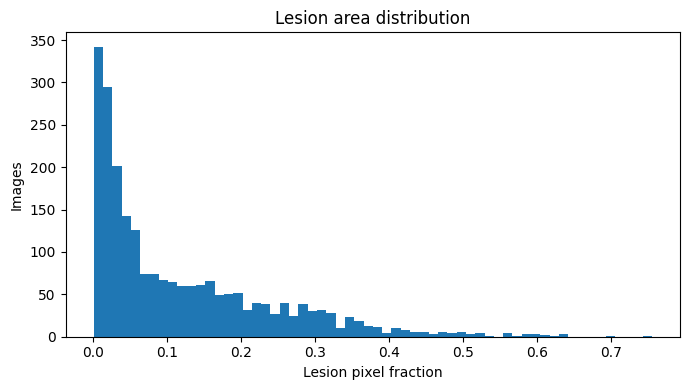

size_bin
<1%      254
1-5%     720
5-15%    587
>15%     710
Name: count, dtype: int64


In [8]:
# ============================================================
# 6a. CLASS-IMBALANCE DIAGNOSTIC
# ============================================================
frac = dataset_df["lesion_frac"].values
pos_rate = float(frac.mean())

print(f"Mean lesion pixel fraction : {pos_rate:.4f}  ({pos_rate*100:.2f}%)")
print(f"Median                     : {np.median(frac):.4f}")
print(f"Background : foreground    : {(1-pos_rate)/max(pos_rate,1e-9):.1f} : 1")
print(f"Images with <1% lesion     : {int((frac < 0.01).sum())}")
print(f"Images with <5% lesion     : {int((frac < 0.05).sum())}")

dataset_df["size_bin"] = pd.cut(dataset_df["lesion_frac"], bins=SIZE_BIN_EDGES,
                                 labels=SIZE_BIN_LABELS)

plt.figure(figsize=(7, 4))
plt.hist(frac, bins=60)
plt.xlabel("Lesion pixel fraction"); plt.ylabel("Images")
plt.title("Lesion area distribution")
plt.tight_layout()
plt.savefig(RUN_DIR / "lesion_area_distribution.png", dpi=140)
plt.show()

print(dataset_df["size_bin"].value_counts().sort_index())


In [9]:
# ============================================================
# 7. STRATIFIED SPLIT
# ============================================================
bins = pd.qcut(dataset_df["lesion_frac"].rank(method="first"),
               q=5, labels=False, duplicates="drop")

train_df, val_df = train_test_split(
    dataset_df, test_size=VAL_FRACTION, random_state=SEED,
    shuffle=True, stratify=bins,
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

assert set(train_df["image_id"]).isdisjoint(set(val_df["image_id"])), "LEAK!"
assert len(train_df) >= BATCH_SIZE, "Train set smaller than one batch."

print("Total :", len(dataset_df), " Train :", len(train_df), " Val :", len(val_df))
print("Mean lesion frac  train:", round(train_df["lesion_frac"].mean(), 4),
      " val:", round(val_df["lesion_frac"].mean(), 4))
print("Split: PASS (stratified, no overlap)")
print()
print("Train size-bin counts:")
print(train_df["size_bin"].value_counts().sort_index())


Total : 2271  Train : 1816  Val : 455
Mean lesion frac  train: 0.1172  val: 0.1177
Split: PASS (stratified, no overlap)

Train size-bin counts:
size_bin
<1%      195
1-5%     584
5-15%    465
>15%     572
Name: count, dtype: int64


In [10]:
# ============================================================
# 8. LOADER + tf.data  (letterbox baseline + lesion-centered crop)
# ============================================================
def letterbox(img, size, interp, pad_value=0):
    """Aspect-preserving resize into a size x size canvas."""
    h, w = img.shape[:2]
    scale = size / max(h, w)
    nh, nw = max(1, int(round(h * scale))), max(1, int(round(w * scale)))
    resized = cv2.resize(img, (nw, nh), interpolation=interp)

    top, left = (size - nh) // 2, (size - nw) // 2
    if resized.ndim == 3:
        canvas = np.full((size, size, resized.shape[2]), pad_value, dtype=resized.dtype)
        canvas[top:top + nh, left:left + nw, :] = resized
    else:
        canvas = np.full((size, size), pad_value, dtype=resized.dtype)
        canvas[top:top + nh, left:left + nw] = resized
    return canvas


def _lesion_crop_box(h, w, bx0, by0, bx1, by1, rng):
    """Pick a square crop box (in pixel coords) around a lesion bbox with a
    random margin, clipped to stay inside the image. Falls back gracefully
    when the jittered box would run off the edge."""
    bw, bh = (bx1 - bx0) * w, (by1 - by0) * h
    cx, cy = (bx0 + bx1) / 2.0 * w, (by0 + by1) / 2.0 * h

    margin = rng.uniform(CROP_MARGIN_LOW, CROP_MARGIN_HIGH)
    side = max(bw, bh) * margin
    side = max(side, CROP_MIN_FRAC_OF_IMG * min(h, w))
    side = min(side, min(h, w))   # never larger than the image itself

    # small random shift of the crop center so the lesion isn't always dead-center
    jitter = side * 0.10
    cx += rng.uniform(-jitter, jitter)
    cy += rng.uniform(-jitter, jitter)

    x0 = int(round(np.clip(cx - side / 2, 0, w - side)))
    y0 = int(round(np.clip(cy - side / 2, 0, h - side)))
    return x0, y0, int(round(side)), int(round(side))


def _load_np(image_path, mask_path, bbox, do_crop_flag):
    image_path = image_path.numpy().decode("utf-8")
    mask_path = mask_path.numpy().decode("utf-8")
    bbox = bbox.numpy()
    do_crop = bool(do_crop_flag.numpy())

    image = safe_imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Unreadable image: {image_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Unreadable mask: {mask_path}")

    h, w = image.shape[:2]
    has_bbox = bool(np.all(np.isfinite(bbox)))

    if do_crop and has_bbox:
        rng = np.random.default_rng()
        x0, y0, cw, ch = _lesion_crop_box(h, w, *bbox.tolist(), rng)
        image = image[y0:y0 + ch, x0:x0 + cw]
        mask = mask[y0:y0 + ch, x0:x0 + cw]

    if LETTERBOX_RESIZE:
        image = letterbox(image, IMG_SIZE, cv2.INTER_AREA, 0)
        mask = letterbox(mask, IMG_SIZE, cv2.INTER_NEAREST, 0)
    else:
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

    return (np.ascontiguousarray(image, dtype=np.float32),
            np.ascontiguousarray((mask > 127).astype(np.float32)[..., None]))


def tf_load(image_path, mask_path, bbox, training):
    do_crop = training and (tf.random.uniform([]) < TRAIN_CROP_PROB)
    image, mask = tf.py_function(
        _load_np, [image_path, mask_path, bbox, do_crop],
        [tf.float32, tf.float32])
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask


In [11]:
# ============================================================
# 8b. OVERSAMPLING BY LESION-SIZE BIN (NEW)
#     Small-lesion images are a minority of the training set (see the
#     bin counts printed in Section 7). Rather than let the natural
#     frequency decide how often the model sees them, each size bin
#     becomes its own tf.data.Dataset (looping, shuffled) and
#     sample_from_datasets mixes them at fixed target weights every
#     epoch -- so <1% and 1-5% lesions show up far more often than
#     their raw count would produce.
# ============================================================
def _bin_dataset(df_bin, training):
    paths = df_bin["image_path"].values
    masks = df_bin["mask_path"].values
    bbox = df_bin[["bbox_x0", "bbox_y0", "bbox_x1", "bbox_y1"]].values.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths, masks, bbox))
    if training:
        ds = ds.shuffle(max(len(df_bin), 1), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.repeat()
    ds = ds.map(lambda p, m, b: tf_load(p, m, b, training),
                num_parallel_calls=tf.data.AUTOTUNE, deterministic=not training)
    return ds


def make_train_dataset_oversampled(df):
    present_bins = [b for b in SIZE_BIN_LABELS if (df["size_bin"] == b).sum() > 0]
    weights = np.array([SIZE_BIN_TARGET_FREQ[b] for b in present_bins], dtype=np.float64)
    weights = weights / weights.sum()

    bin_datasets = [_bin_dataset(df[df["size_bin"] == b].reset_index(drop=True), training=True)
                    for b in present_bins]

    print("Oversampling weights (renormalized over present bins):")
    for b, wgt in zip(present_bins, weights):
        n = int((df["size_bin"] == b).sum())
        print(f"  {b:<8} n={n:<5} natural_freq={n/len(df):.3f}  target_freq={wgt:.3f}")

    ds = tf.data.Dataset.sample_from_datasets(bin_datasets, weights=weights.tolist(), seed=SEED)
    return ds


def make_dataset(df, training):
    if training and OVERSAMPLE_SMALL_LESIONS:
        ds = make_train_dataset_oversampled(df)
    else:
        paths = df["image_path"].values
        masks = df["mask_path"].values
        bbox = df[["bbox_x0", "bbox_y0", "bbox_x1", "bbox_y1"]].values.astype(np.float32)
        ds = tf.data.Dataset.from_tensor_slices((paths, masks, bbox))
        if training:
            ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda p, m, b: tf_load(p, m, b, training),
                    num_parallel_calls=tf.data.AUTOTUNE, deterministic=not training)

    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE, deterministic=False)

    if USE_DEEP_SUP:
        ds = ds.map(add_deep_sup_targets, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(BATCH_SIZE, drop_remainder=training)
    return ds.prefetch(tf.data.AUTOTUNE)


def main_target(y):
    """Extract the full-resolution mask regardless of deep-supervision mode."""
    return y["head_out"] if isinstance(y, dict) else y


In [12]:
# ============================================================
# 9. AUGMENTATION (orientation-safe, geometry-consistent)
#    flip + affine + color jitter unchanged from before; elastic
#    deformation and cutout are NEW (Section intro table).
# ============================================================
def _rand_affine(image, mask):
    """Rotation +/-15 deg, shift +/-8%, zoom 0.9-1.1 -- identical for both."""
    angle = tf.random.uniform([], -15.0, 15.0) * math.pi / 180.0
    zoom = tf.random.uniform([], 0.90, 1.10)
    dx = tf.random.uniform([], -0.08, 0.08) * IMG_SIZE
    dy = tf.random.uniform([], -0.08, 0.08) * IMG_SIZE

    cos_a, sin_a = tf.cos(angle) / zoom, tf.sin(angle) / zoom
    cx = cy = IMG_SIZE / 2.0

    a2 = cx - cx * cos_a + cy * sin_a + dx
    b2 = cy - cx * sin_a - cy * cos_a + dy
    transform = tf.stack([cos_a, -sin_a, a2, sin_a, cos_a, b2, 0.0, 0.0])[None, :]

    stacked = tf.concat([image, mask], axis=-1)[None, ...]
    warped = tf.raw_ops.ImageProjectiveTransformV3(
        images=stacked, transforms=transform,
        output_shape=tf.constant([IMG_SIZE, IMG_SIZE], tf.int32),
        interpolation="BILINEAR", fill_mode="CONSTANT", fill_value=0.0,
    )[0]

    return warped[..., :3], tf.cast(warped[..., 3:] > 0.5, tf.float32)


def _elastic_deform_np(image, mask, alpha, sigma):
    """Classic Simard-style elastic deformation via a smoothed random
    displacement field, applied identically to image and mask."""
    shape = image.shape[:2]
    dx = cv2.GaussianBlur((np.random.rand(*shape).astype(np.float32) * 2 - 1),
                          (0, 0), sigma) * alpha
    dy = cv2.GaussianBlur((np.random.rand(*shape).astype(np.float32) * 2 - 1),
                          (0, 0), sigma) * alpha

    xs, ys = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
    map_x = (xs + dx).astype(np.float32)
    map_y = (ys + dy).astype(np.float32)

    warped_img = cv2.remap(image, map_x, map_y, interpolation=cv2.INTER_LINEAR,
                           borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    warped_mask = cv2.remap(mask, map_x, map_y, interpolation=cv2.INTER_NEAREST,
                            borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    return warped_img, warped_mask[..., None] if warped_mask.ndim == 2 else warped_mask


def _elastic_deform_tf(image, mask):
    alpha = tf.random.uniform([], *ELASTIC_ALPHA_RANGE)
    sigma = tf.random.uniform([], *ELASTIC_SIGMA_RANGE)
    img_out, mask_out = tf.numpy_function(
        _elastic_deform_np, [image, mask, alpha, sigma], [tf.float32, tf.float32])
    img_out.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask_out.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return img_out, tf.cast(mask_out > 0.5, tf.float32)


def _cutout(image, mask):
    """Zero out a random square patch of the IMAGE only (never the mask) --
    forces the model to rely on context rather than memorizing local texture.
    Patch placement avoids fully blanking a very small lesion by biasing away
    from the mask centroid when the lesion is tiny."""
    frac = tf.random.uniform([], *CUTOUT_FRAC_RANGE)
    side = tf.cast(frac * IMG_SIZE, tf.int32)
    cy = tf.random.uniform([], 0, IMG_SIZE, dtype=tf.int32)
    cx = tf.random.uniform([], 0, IMG_SIZE, dtype=tf.int32)

    y0 = tf.clip_by_value(cy - side // 2, 0, IMG_SIZE)
    x0 = tf.clip_by_value(cx - side // 2, 0, IMG_SIZE)
    y1 = tf.clip_by_value(y0 + side, 0, IMG_SIZE)
    x1 = tf.clip_by_value(x0 + side, 0, IMG_SIZE)

    yy = tf.range(IMG_SIZE)[:, None]
    xx = tf.range(IMG_SIZE)[None, :]
    hole = (yy >= y0) & (yy < y1) & (xx >= x0) & (xx < x1)
    hole = tf.cast(hole, tf.float32)[..., None]

    return image * (1.0 - hole)


def augment(image, mask):
    if tf.random.uniform([]) > 0.5:                 # horizontal flip only
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)

    if tf.random.uniform([]) > 0.3:
        image, mask = _rand_affine(image, mask)

    if tf.random.uniform([]) < ELASTIC_PROB:
        image, mask = _elastic_deform_tf(image, mask)

    image = tf.image.random_brightness(image, 20.0)          # on [0,255]
    image = tf.image.random_contrast(image, 0.85, 1.15)
    image = tf.image.random_saturation(image, 0.85, 1.15)
    image = tf.image.random_hue(image, 0.02)
    image = tf.clip_by_value(image, 0.0, 255.0)

    if tf.random.uniform([]) < CUTOUT_PROB:
        image = _cutout(image, mask)

    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask


def add_deep_sup_targets(image, mask):
    """Targets keyed by output name so Keras matches them unambiguously."""
    m2 = tf.image.resize(mask, [IMG_SIZE // 2, IMG_SIZE // 2], method="nearest")
    m4 = tf.image.resize(mask, [IMG_SIZE // 4, IMG_SIZE // 4], method="nearest")
    return image, {"head_out": mask, "aux_out_2": m2, "aux_out_4": m4}


In [13]:
# ============================================================
# 9b. BUILD train_ds / val_ds
# ============================================================
train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)

_xb, _yb = next(iter(train_ds))
_main = main_target(_yb)

print("Image batch:", _xb.shape, "range",
      float(tf.reduce_min(_xb)), "-", float(tf.reduce_max(_xb)))
print("Mask batch :", _main.shape, "unique", np.unique(_main.numpy()))
assert np.all(np.isfinite(_xb.numpy()))
assert set(np.unique(_main.numpy())).issubset({0.0, 1.0})
print("Pipeline: PASS")


I0000 00:00:1790090335.626474      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


Oversampling weights (renormalized over present bins):
  <1%      n=195   natural_freq=0.107  target_freq=0.350
  1-5%     n=584   natural_freq=0.322  target_freq=0.300
  5-15%    n=465   natural_freq=0.256  target_freq=0.200
  >15%     n=572   natural_freq=0.315  target_freq=0.150
Image batch: (4, 320, 320, 3) range 0.0 - 255.0
Mask batch : (4, 320, 320, 1) unique [0. 1.]
Pipeline: PASS


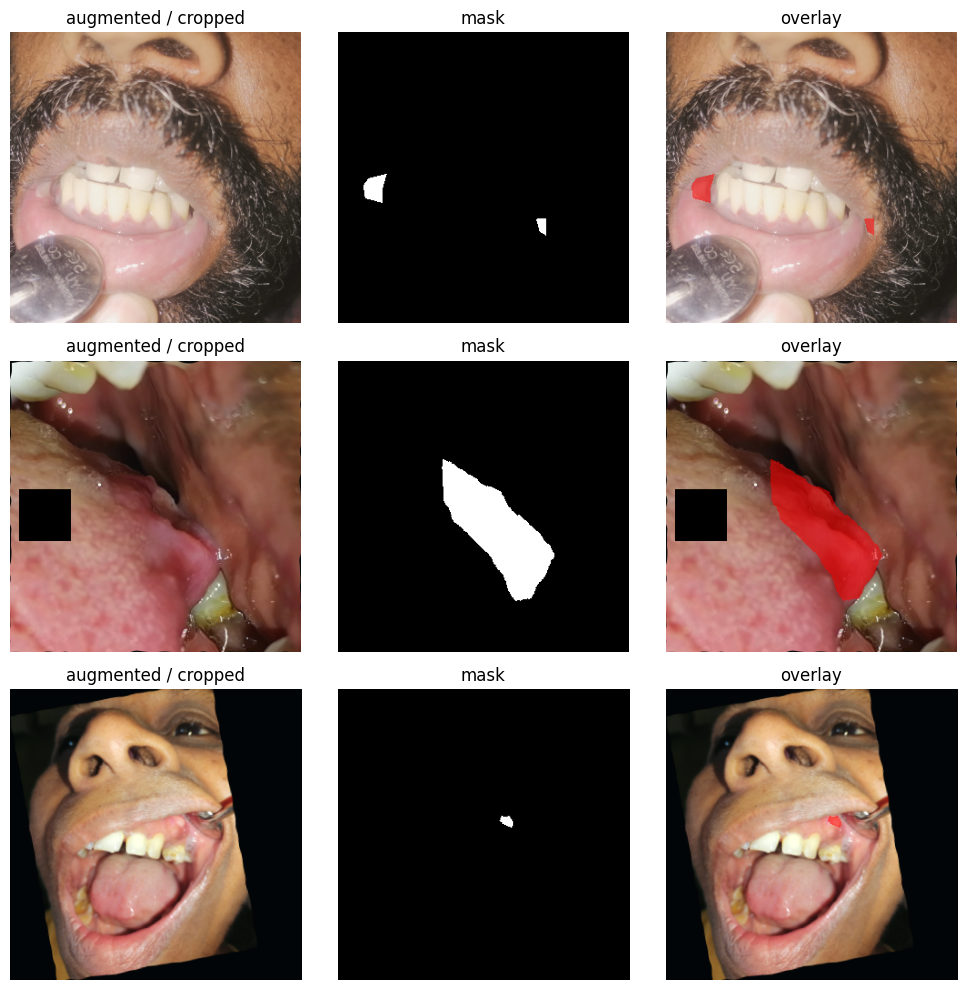

Lesion-fraction of these 3 mask crops: [0.0068, 0.0827, 0.0012] -- should generally read higher than the raw lesion_frac column
since TRAIN_CROP_PROB = 0.7 of batches are lesion-centered crops.


In [14]:
# ============================================================
# 9c. VISUAL CHECK OF AUGMENTED / CROPPED BATCH
# ============================================================
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i in range(3):
    img = _xb[i].numpy().astype(np.uint8)
    msk = _main[i].numpy()[..., 0]
    ov = img.copy()
    sel = msk > 0.5
    ov[sel] = (0.45 * ov[sel] + 0.55 * np.array([255, 0, 0])).astype(np.uint8)

    axes[i, 0].imshow(img);              axes[i, 0].set_title("augmented / cropped")
    axes[i, 1].imshow(msk, cmap="gray"); axes[i, 1].set_title("mask")
    axes[i, 2].imshow(ov);               axes[i, 2].set_title("overlay")
    for c in range(3):
        axes[i, c].axis("off")

plt.tight_layout()
plt.savefig(RUN_DIR / "augmentation_check.png", dpi=140)
plt.show()
print("Lesion-fraction of these 3 mask crops:",
      [round(float((_main[i].numpy() > 0.5).mean()), 4) for i in range(3)],
      "-- should generally read higher than the raw lesion_frac column")
print("since TRAIN_CROP_PROB =", TRAIN_CROP_PROB, "of batches are lesion-centered crops.")


In [15]:
# ============================================================
# 10. LOSSES + METRICS (registered so model.save() works)
# ============================================================
SMOOTH = 1e-6


def _flat(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    n = tf.shape(y_true)[0]
    return tf.reshape(y_true, [n, -1]), tf.reshape(y_pred, [n, -1])


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def dice_coef(y_true, y_pred):
    yt, yp = _flat(y_true, y_pred)
    inter = tf.reduce_sum(yt * yp, axis=1)
    denom = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1)
    return tf.reduce_mean((2.0 * inter + SMOOTH) / (denom + SMOOTH))


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def iou_coef(y_true, y_pred):
    yt, yp = _flat(y_true, y_pred)
    inter = tf.reduce_sum(yt * yp, axis=1)
    union = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1) - inter
    return tf.reduce_mean((inter + SMOOTH) / (union + SMOOTH))


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def bin_dice(y_true, y_pred):
    """Hard Dice at 0.5 -- the reported number."""
    yt, yp = _flat(y_true, tf.cast(y_pred > 0.5, tf.float32))
    inter = tf.reduce_sum(yt * yp, axis=1)
    denom = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1)
    return tf.reduce_mean((2.0 * inter + SMOOTH) / (denom + SMOOTH))


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def bin_iou(y_true, y_pred):
    yt, yp = _flat(y_true, tf.cast(y_pred > 0.5, tf.float32))
    inter = tf.reduce_sum(yt * yp, axis=1)
    union = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1) - inter
    return tf.reduce_mean((inter + SMOOTH) / (union + SMOOTH))


def tversky_index(y_true, y_pred, alpha=TVERSKY_ALPHA, beta=TVERSKY_BETA):
    yt, yp = _flat(y_true, y_pred)
    tp = tf.reduce_sum(yt * yp, axis=1)
    fp = tf.reduce_sum((1.0 - yt) * yp, axis=1)
    fn = tf.reduce_sum(yt * (1.0 - yp), axis=1)
    return tf.reduce_mean((tp + SMOOTH) / (tp + alpha * fp + beta * fn + SMOOTH))


def focal_tversky_loss(y_true, y_pred, gamma=TVERSKY_GAMMA):
    return tf.pow(1.0 - tversky_index(y_true, y_pred), gamma)


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def combined_loss(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return BCE_WEIGHT * bce + TVERSKY_WEIGHT * focal_tversky_loss(y_true, y_pred)


METRICS = [dice_coef, iou_coef, bin_dice, bin_iou]

# quick numerical sanity check
_t = tf.constant(np.random.randint(0, 2, (2, 8, 8, 1)).astype(np.float32))
_p = tf.constant(np.random.rand(2, 8, 8, 1).astype(np.float32))
for fn in (dice_coef, iou_coef, bin_dice, bin_iou, combined_loss):
    v = float(fn(_t, _p))
    assert np.isfinite(v), f"{fn.__name__} not finite"
assert abs(float(dice_coef(_t, _t)) - 1.0) < 1e-4, "dice_coef(y,y) != 1"
assert float(combined_loss(_t, _t)) < 0.05, "loss on perfect prediction too high"
del _t, _p

print("Losses and metrics defined and sanity-checked.")
print("Loss = 0.5*BCE + 0.5*FocalTversky(alpha=0.3, beta=0.7, gamma=0.75)")


Losses and metrics defined and sanity-checked.
Loss = 0.5*BCE + 0.5*FocalTversky(alpha=0.3, beta=0.7, gamma=0.75)


In [16]:
# ============================================================
# 11. LAYER-NAME REGISTRY
#    Guarantees the duplicate-name crash can never happen again.
# ============================================================
class NameRegistry:
    """Hands out guaranteed-unique layer names and records every one."""

    def __init__(self):
        self.used = set()

    def reset(self):
        self.used = set()

    def __call__(self, name):
        if name in self.used:
            raise ValueError(
                f"Duplicate layer name generated: '{name}'. "
                "This is a builder bug -- fix the name prefix."
            )
        self.used.add(name)
        return name


NAMES = NameRegistry()
print("Name registry ready. Every layer name is asserted unique at build time.")


Name registry ready. Every layer name is asserted unique at build time.


In [17]:
# ============================================================
# 12. MOBILE-UNET BLOCKS (100% depthwise separable)
# ============================================================
@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
class CBAM(layers.Layer):
    """Channel + spatial attention. No Lambda -> clean .keras serialization."""

    def __init__(self, reduction_ratio=8, spatial_kernel=7, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = int(reduction_ratio)
        self.spatial_kernel = int(spatial_kernel)

    def build(self, input_shape):
        c = int(input_shape[-1])
        r = max(c // self.reduction_ratio, 4)
        self.mlp1 = layers.Dense(r, activation="relu", name="ch_reduce")
        self.mlp2 = layers.Dense(c, activation=None, name="ch_expand")
        self.sp_conv = layers.Conv2D(1, self.spatial_kernel, padding="same",
                                     activation="sigmoid", name="sp_conv")
        super().build(input_shape)

    def call(self, x):
        avg = tf.reduce_mean(x, axis=[1, 2])
        mx = tf.reduce_max(x, axis=[1, 2])
        att = tf.nn.sigmoid(self.mlp2(self.mlp1(avg)) + self.mlp2(self.mlp1(mx)))
        x = x * att[:, None, None, :]

        sp = tf.concat([tf.reduce_mean(x, -1, keepdims=True),
                        tf.reduce_max(x, -1, keepdims=True)], axis=-1)
        return x * self.sp_conv(sp)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"reduction_ratio": self.reduction_ratio,
                    "spatial_kernel": self.spatial_kernel})
        return cfg


def sep_block(x, filters, prefix, act, dilation=1):
    """Separable conv -> BN -> activation."""
    x = layers.SeparableConv2D(
        filters, 3, padding="same", use_bias=False, dilation_rate=dilation,
        name=NAMES(f"{prefix}_sep"))(x)
    x = layers.BatchNormalization(name=NAMES(f"{prefix}_bn"))(x)
    return layers.Activation(act, name=NAMES(f"{prefix}_act"))(x)


def residual_sep_block(x, filters, prefix, act, dropout=0.0):
    """Two separable convs + 1x1 projection shortcut."""
    shortcut = layers.Conv2D(filters, 1, padding="same", use_bias=False,
                             name=NAMES(f"{prefix}_sc"))(x)
    shortcut = layers.BatchNormalization(name=NAMES(f"{prefix}_sc_bn"))(shortcut)

    y = sep_block(x, filters, f"{prefix}_a", act)
    if dropout > 0:
        y = layers.SpatialDropout2D(dropout, name=NAMES(f"{prefix}_inner_drop"))(y)
    y = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False,
                               name=NAMES(f"{prefix}_b_sep"))(y)
    y = layers.BatchNormalization(name=NAMES(f"{prefix}_b_bn"))(y)

    out = layers.Add(name=NAMES(f"{prefix}_add"))([shortcut, y])
    return layers.Activation(act, name=NAMES(f"{prefix}_out"))(out)


def double_block(x, filters, prefix, residual, act, dropout):
    """Either two plain separable convs (v1 style) or one residual block."""
    if residual:
        return residual_sep_block(x, filters, prefix, act, dropout)
    x = sep_block(x, filters, f"{prefix}_a", act)
    x = sep_block(x, filters, f"{prefix}_b", act)
    if dropout > 0:
        x = layers.SpatialDropout2D(dropout, name=NAMES(f"{prefix}_inner_drop"))(x)
    return x


def attention_gate(skip, gating, filters, prefix):
    """Additive attention gate applied to a skip connection."""
    g = layers.Conv2D(filters, 1, padding="same", name=NAMES(f"{prefix}_g"))(gating)
    s = layers.Conv2D(filters, 1, padding="same", name=NAMES(f"{prefix}_x"))(skip)
    a = layers.Add(name=NAMES(f"{prefix}_add"))([g, s])
    a = layers.Activation("relu", name=NAMES(f"{prefix}_relu"))(a)
    psi = layers.Conv2D(1, 1, padding="same", activation="sigmoid",
                        name=NAMES(f"{prefix}_psi"))(a)
    return layers.Multiply(name=NAMES(f"{prefix}_mul"))([skip, psi])


def sep_aspp(x, filters, prefix, act, rates=(1, 2, 4, 8)):
    """Separable atrous spatial pyramid. Branch width is capped so the
    48-filter variant does not explode to millions of parameters."""
    branch_f = int(min(filters, ASPP_MAX_FILTERS))

    branches = [layers.Conv2D(branch_f, 1, padding="same", use_bias=False,
                              name=NAMES(f"{prefix}_b0_conv"))(x)]
    for i, r in enumerate(rates[1:], start=1):
        branches.append(sep_block(x, branch_f, f"{prefix}_b{i}", act, dilation=r))

    pooled = layers.GlobalAveragePooling2D(
        keepdims=True, name=NAMES(f"{prefix}_gap"))(x)
    pooled = layers.Conv2D(branch_f, 1, padding="same", use_bias=False,
                           name=NAMES(f"{prefix}_gap_conv"))(pooled)
    pooled = layers.UpSampling2D(size=(int(x.shape[1]), int(x.shape[2])),
                                 interpolation="bilinear",
                                 name=NAMES(f"{prefix}_gap_up"))(pooled)
    branches.append(pooled)

    merged = layers.Concatenate(name=NAMES(f"{prefix}_cat"))(branches)
    merged = layers.Conv2D(branch_f, 1, padding="same", use_bias=False,
                           name=NAMES(f"{prefix}_proj"))(merged)
    merged = layers.BatchNormalization(name=NAMES(f"{prefix}_proj_bn"))(merged)
    return layers.Activation(act, name=NAMES(f"{prefix}_proj_act"))(merged)


print("Mobile-UNet blocks defined (no external backbone, no pretrained weights).")


Mobile-UNet blocks defined (no external backbone, no pretrained weights).


In [18]:
# ============================================================
# 13. MOBILE-UNET BUILDER
# ============================================================
def build_mobile_unet(img_size, base_filters, depth,
                      residual, gates, cbam, aspp, deep_sup,
                      dropout, act, name="mobile_unet"):
    NAMES.reset()

    inputs = layers.Input(shape=(img_size, img_size, 3), name=NAMES("input_image"))
    x = layers.Rescaling(1.0 / 255.0, name=NAMES("rescale"))(inputs)

    # ---------------- Encoder ----------------
    skips, filters = [], base_filters
    for i in range(depth):
        enc_drop = dropout * 0.5 if i >= depth - 2 else 0.0
        x = double_block(x, filters, f"enc{i}", residual, act, enc_drop)
        skips.append(x)
        x = layers.MaxPooling2D(2, name=NAMES(f"enc{i}_pool"))(x)
        filters *= 2

    # ---------------- Bottleneck ----------------
    if aspp:
        x = sep_aspp(x, filters, "bneck_aspp", act)
        filters = int(x.shape[-1])
    else:
        x = double_block(x, filters, "bneck", residual, act, 0.0)

    if cbam:
        x = CBAM(CBAM_REDUCTION, name=NAMES("bottleneck_cbam"))(x)

    if dropout > 0:
        x = layers.SpatialDropout2D(dropout, name=NAMES("bottleneck_drop"))(x)

    # ---------------- Decoder ----------------
    aux_outputs = {}
    dec_filters = base_filters * (2 ** (depth - 1))

    for i in reversed(range(depth)):
        x = layers.UpSampling2D(2, interpolation="bilinear",
                                name=NAMES(f"dec{i}_up"))(x)

        skip = skips[i]
        if gates:
            skip = attention_gate(skip, x, max(dec_filters // 2, 8), f"dec{i}_gate")

        x = layers.Concatenate(name=NAMES(f"dec{i}_cat"))([x, skip])
        x = double_block(x, dec_filters, f"dec{i}", residual, act,
                         dropout if i >= 2 else 0.0)

        if deep_sup and i in (1, 2):
            head_name = f"aux_out_{2 ** i}"
            aux_outputs[head_name] = layers.Conv2D(
                1, 1, activation="sigmoid", dtype="float32",
                name=NAMES(head_name))(x)

        dec_filters = max(dec_filters // 2, base_filters)

    main_out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32",
                             name=NAMES("head_out"))(x)

    if deep_sup:
        outputs = [main_out, aux_outputs["aux_out_2"], aux_outputs["aux_out_4"]]
        model = models.Model(inputs, outputs, name=name)
    else:
        model = models.Model(inputs, main_out, name=name)

    all_names = [l.name for l in model.layers]
    dupes = [n for n, c in Counter(all_names).items() if c > 1]
    assert not dupes, f"Duplicate layer names survived the registry: {dupes}"

    return model


print("Builder defined.")


Builder defined.


### Build-time self-test

All four variants are constructed and immediately discarded. If any variant would
raise a duplicate-name error, it surfaces here — before any training time is spent.


In [19]:
# ============================================================
# 14b. SELF-TEST -- BUILD EVERY VARIANT (optional, see Section 2)
# ============================================================
if not RUN_VARIANT_SELF_TEST:
    print("Skipped (RUN_VARIANT_SELF_TEST = False in Section 2).")
    print("The selected variant is still verified by the hard preflight below.")
else:
    print(f"{'variant':<18}{'params':>12}{'FP32 MB':>10}{'outputs':>10}  status")
    print("-" * 64)

    _size_table = {}

    for _name, _cfg in VARIANTS.items():
        tf.keras.backend.clear_session()
        try:
            _m = build_mobile_unet(
                img_size=_cfg["img_size"], base_filters=_cfg["base_filters"],
                depth=_cfg["depth"], residual=_cfg["residual"], gates=_cfg["gates"],
                cbam=_cfg["cbam"], aspp=_cfg["aspp"], deep_sup=_cfg["deep_sup"],
                dropout=_cfg["dropout"], act=_cfg["activation"], name=f"probe_{_name}",
            )
            _p = int(_m.count_params())
            _mb = _p * 4 / (1024 ** 2)
            _n_out = len(_m.outputs)
            _size_table[_name] = {"params": _p, "fp32_mb": round(_mb, 2)}
            print(f"{_name:<18}{_p:>12,}{_mb:>10.2f}{_n_out:>10}  OK")
            del _m
        except Exception as e:
            print(f"{_name:<18}{'-':>12}{'-':>10}{'-':>10}  FAIL: {e}")
            raise

    print("-" * 64)
    print(f"{'v1_original':<18}{311319:>12,}{311319 * 4 / 1024 ** 2:>10.2f}{1:>10}  reference")
    print()
    print("All variants build cleanly. No duplicate layer names.")

    tf.keras.backend.clear_session()


Skipped (RUN_VARIANT_SELF_TEST = False in Section 2).
The selected variant is still verified by the hard preflight below.


In [20]:
# ============================================================
# 15. BUILD THE SELECTED MODEL
# ============================================================
tf.keras.backend.clear_session()
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

model = build_mobile_unet(
    img_size=IMG_SIZE,
    base_filters=BASE_FILTERS,
    depth=DEPTH,
    residual=USE_RESIDUAL,
    gates=USE_GATES,
    cbam=USE_CBAM,
    aspp=USE_ASPP,
    deep_sup=USE_DEEP_SUP,
    dropout=DROPOUT,
    act=ACTIVATION,
    name=f"lesion_{VARIANT}",
)

total_params = int(model.count_params())
trainable_params = int(sum(np.prod(v.shape) for v in model.trainable_weights))
non_trainable_params = total_params - trainable_params
fp32_mb = total_params * 4 / (1024 ** 2)

V1_PARAMS, V1_DICE, V1_IOU = 311319, 0.30052751, 0.19818199

print("=" * 66)
print("MODEL SIZE")
print("=" * 66)
print(f"{'Model':<24}{model.name}")
print(f"{'Total params':<24}{total_params:>14,}")
print(f"{'Trainable params':<24}{trainable_params:>14,}")
print(f"{'Non-trainable (BN)':<24}{non_trainable_params:>14,}")
print(f"{'FP32 weights (MB)':<24}{fp32_mb:>14.2f}")
print(f"{'FP16 activations (~)':<24}{'mixed_float16 active -- ~2x less activation RAM':>14}")
print(f"{'INT8 estimate (MB)':<24}{total_params / (1024 ** 2):>14.2f}")
print("-" * 66)
print(f"{'v1 total params':<24}{V1_PARAMS:>14,}")
print(f"{'v1 FP32 (MB)':<24}{V1_PARAMS * 4 / 1024 ** 2:>14.2f}")
print(f"{'Capacity vs v1':<24}{total_params / V1_PARAMS:>13.2f}x")
print("=" * 66)
print("Separable conv layers :",
      sum(1 for l in model.layers if isinstance(l, layers.SeparableConv2D)))
print("Total layers          :", len(model.layers))
print("Output(s)             :", model.output_shape)
print("Architecture family   : Mobile-UNet only (no external backbone)")


MODEL SIZE
Model                   lesion_mu_b_tuned
Total params                 1,552,563
Trainable params             1,543,731
Non-trainable (BN)               8,832
FP32 weights (MB)                 5.92
FP16 activations (~)    mixed_float16 active -- ~2x less activation RAM
INT8 estimate (MB)                1.48
------------------------------------------------------------------
v1 total params                311,319
v1 FP32 (MB)                      1.19
Capacity vs v1                   4.99x
Separable conv layers : 18
Total layers          : 126
Output(s)             : (None, 320, 320, 1)
Architecture family   : Mobile-UNet only (no external backbone)


In [21]:
# ============================================================
# 16. HARD PREFLIGHT -- NOTHING TRAINS BEFORE THIS PASSES
# ============================================================
checks = []

vx, vy = next(iter(val_ds))
vy_main = main_target(vy)

out = model(vx, training=False)
pred = out[0] if isinstance(out, (list, tuple)) else out

checks.append(("output shape matches target", tuple(pred.shape) == tuple(vy_main.shape)))
checks.append(("prediction finite", bool(np.all(np.isfinite(pred.numpy())))))
checks.append(("prediction in [0,1]",
               float(pred.numpy().min()) >= 0.0 and float(pred.numpy().max()) <= 1.0))
checks.append(("masks binary", set(np.unique(vy_main.numpy())).issubset({0.0, 1.0})))
checks.append(("images in [0,255]",
               float(vx.numpy().min()) >= 0.0 and float(vx.numpy().max()) <= 255.0))

loss_val = float(combined_loss(vy_main, pred))
checks.append(("loss finite", bool(np.isfinite(loss_val))))
checks.append(("train batches > 0", len(train_df) // BATCH_SIZE > 0))
checks.append(("no train/val leak",
               set(train_df["image_id"]).isdisjoint(set(val_df["image_id"]))))
checks.append(("unique layer names",
               len({l.name for l in model.layers}) == len(model.layers)))

if USE_DEEP_SUP:
    checks.append(("3 outputs for deep supervision", len(model.outputs) == 3))
    checks.append(("aux target keys match outputs",
                   set(vy.keys()) == {"head_out", "aux_out_2", "aux_out_4"}))

with tf.GradientTape() as tape:
    o = model(vx, training=True)
    p = o[0] if isinstance(o, (list, tuple)) else o
    l = combined_loss(vy_main, p)
grads = tape.gradient(l, model.trainable_weights)
nonzero = sum(1 for g in grads if g is not None and float(tf.reduce_max(tf.abs(g))) > 0)
checks.append((f"gradients flow ({nonzero}/{len(grads)})", nonzero > 0.8 * len(grads)))

print(f"{'check':<44}{'result':>8}")
print("-" * 52)
for label, ok in checks:
    print(f"{label:<44}{'PASS' if ok else 'FAIL':>8}")
print("-" * 52)
assert all(ok for _, ok in checks), "STOP: preflight failed -- fix before training."
print("Preflight: ALL PASS")


check                                         result
----------------------------------------------------
output shape matches target                     PASS
prediction finite                               PASS
prediction in [0,1]                             PASS
masks binary                                    PASS
images in [0,255]                               PASS
loss finite                                     PASS
train batches > 0                               PASS
no train/val leak                               PASS
unique layer names                              PASS
gradients flow (131/131)                        PASS
----------------------------------------------------
Preflight: ALL PASS


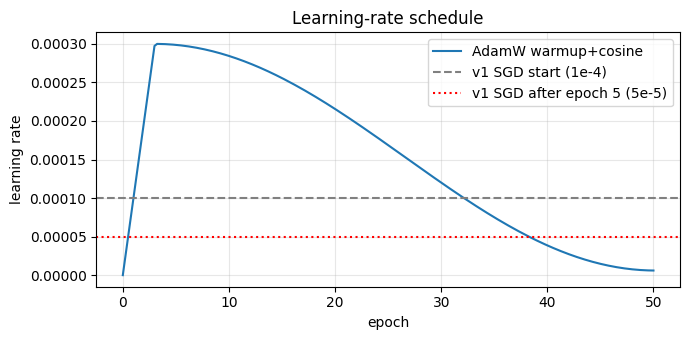

Steps/epoch (weight updates): 113
Physical batch  : 4  Grad accum steps: 4  Effective batch: 16
Monitor     : val_bin_dice
Compile: PASS


In [22]:
# ============================================================
# 17. LR SCHEDULE + COMPILE  (with gradient accumulation)
# ============================================================
steps_per_epoch = max(1, len(train_df) // BATCH_SIZE // GRAD_ACCUM_STEPS)


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
class WarmupCosine(tf.keras.optimizers.schedules.LearningRateSchedule):
    """Linear warmup then cosine decay. Registered so model.save() works."""

    def __init__(self, base_lr, total_steps, warmup_steps, min_lr_ratio=0.02):
        super().__init__()
        self.base_lr = float(base_lr)
        self.total_steps = int(total_steps)
        self.warmup_steps = int(warmup_steps)
        self.min_lr_ratio = float(min_lr_ratio)

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = tf.cast(tf.maximum(self.warmup_steps, 1), tf.float32)
        total = tf.cast(tf.maximum(self.total_steps, 1), tf.float32)

        warm_lr = self.base_lr * (step / warm)
        prog = tf.clip_by_value((step - warm) / tf.maximum(total - warm, 1.0), 0.0, 1.0)
        cos_lr = self.base_lr * (
            self.min_lr_ratio
            + (1.0 - self.min_lr_ratio) * 0.5 * (1.0 + tf.cos(math.pi * prog))
        )
        return tf.where(step < warm, warm_lr, cos_lr)

    def get_config(self):
        return {"base_lr": self.base_lr, "total_steps": self.total_steps,
                "warmup_steps": self.warmup_steps, "min_lr_ratio": self.min_lr_ratio}


schedule = WarmupCosine(
    BASE_LR,
    total_steps=TOTAL_EPOCHS * steps_per_epoch,
    warmup_steps=LR_WARMUP_EPOCHS * steps_per_epoch,
)

optimizer = tf.keras.optimizers.AdamW(
    learning_rate=schedule,
    weight_decay=WEIGHT_DECAY,
    global_clipnorm=GLOBAL_CLIPNORM,
    # gradient_accumulation_steps: accumulates GRAD_ACCUM_STEPS physical
    # batches before each weight update, so EFFECTIVE_BATCH (Section 2)
    # is what the optimizer actually "sees" per step even though only
    # BATCH_SIZE fits in GPU memory at once. Supported natively by
    # tf.keras.optimizers.AdamW (Keras 3 / TF >= 2.16); if your TF build
    # is older this argument is silently ignored -- check the printed
    # optimizer config below and upgrade TF if grad accumulation matters.
    gradient_accumulation_steps=GRAD_ACCUM_STEPS if GRAD_ACCUM_STEPS > 1 else None,
)

if mixed_precision.global_policy().name == "mixed_float16":
    optimizer = mixed_precision.LossScaleOptimizer(optimizer)
    print("LossScaleOptimizer enabled (mixed_float16 training).")

if USE_DEEP_SUP:
    model.compile(
        optimizer=optimizer,
        loss={k: combined_loss for k in DEEP_SUP_WEIGHTS},
        loss_weights=dict(DEEP_SUP_WEIGHTS),
        metrics={"head_out": METRICS},
        steps_per_execution=1,
    )
    MONITOR = "val_head_out_bin_dice"
    DICE_COL, IOU_COL = "head_out_bin_dice", "head_out_bin_iou"
else:
    model.compile(optimizer=optimizer, loss=combined_loss, metrics=METRICS,
                  steps_per_execution=1)
    MONITOR = "val_bin_dice"
    DICE_COL, IOU_COL = "bin_dice", "bin_iou"

lrs = [float(schedule(s)) for s in range(0, TOTAL_EPOCHS * steps_per_epoch,
                                         max(1, steps_per_epoch // 4))]
plt.figure(figsize=(7, 3.5))
plt.plot(np.linspace(0, TOTAL_EPOCHS, len(lrs)), lrs, label="AdamW warmup+cosine")
plt.axhline(1e-4, ls="--", c="gray", label="v1 SGD start (1e-4)")
plt.axhline(5e-5, ls=":", c="r", label="v1 SGD after epoch 5 (5e-5)")
plt.xlabel("epoch"); plt.ylabel("learning rate"); plt.legend(); plt.grid(alpha=.3)
plt.title("Learning-rate schedule")
plt.tight_layout()
plt.savefig(RUN_DIR / "lr_schedule.png", dpi=140)
plt.show()

print("Steps/epoch (weight updates):", steps_per_epoch)
print("Physical batch  :", BATCH_SIZE, " Grad accum steps:", GRAD_ACCUM_STEPS,
      " Effective batch:", EFFECTIVE_BATCH)
print("Monitor     :", MONITOR)
print("Compile: PASS")


In [23]:
# ============================================================
# 18. TRAIN -- up to 50 EPOCHS (no ReduceLROnPlateau; cosine handles decay)
#     A rolling window of the last SWA_LAST_N_EPOCHS checkpoints is kept
#     on disk (SwaCheckpointPool below) so Section 19b can average them.
# ============================================================
BEST_WEIGHTS  = RUN_DIR / f"{VARIANT}_best.weights.h5"
FINAL_MODEL   = RUN_DIR / f"{VARIANT}_final.keras"
FINAL_WEIGHTS = RUN_DIR / f"{VARIANT}_final.weights.h5"
HISTORY_CSV   = RUN_DIR / f"{VARIANT}_history.csv"
SWA_POOL_DIR  = RUN_DIR / f"{VARIANT}_swa_pool"
SWA_POOL_DIR.mkdir(parents=True, exist_ok=True)


class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self._t0)


class SwaCheckpointPool(tf.keras.callbacks.Callback):
    """Keeps weight snapshots for the most recent SWA_LAST_N_EPOCHS epochs
    on disk (rolling window -- oldest is deleted as new ones arrive), so
    Section 19b can average across genuinely late-training checkpoints
    without holding all 50 epochs' weights in memory or on disk at once."""

    def __init__(self, pool_dir, keep_last_n):
        super().__init__()
        self.pool_dir = Path(pool_dir)
        self.keep_last_n = keep_last_n
        self.saved = []

    def on_epoch_end(self, epoch, logs=None):
        path = self.pool_dir / f"epoch_{epoch:03d}.weights.h5"
        self.model.save_weights(str(path))
        self.saved.append(path)
        while len(self.saved) > self.keep_last_n:
            old = self.saved.pop(0)
            old.unlink(missing_ok=True)


timer = EpochTimer()
swa_pool = SwaCheckpointPool(SWA_POOL_DIR, SWA_LAST_N_EPOCHS)
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(BEST_WEIGHTS), monitor=MONITOR, mode="max",
        save_best_only=True, save_weights_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(
        monitor=MONITOR, mode="max", patience=EARLY_STOP_PATIENCE,
        restore_best_weights=True, verbose=1),
    tf.keras.callbacks.CSVLogger(str(HISTORY_CSV), append=False),
    tf.keras.callbacks.TerminateOnNaN(),
    timer,
    swa_pool,
]

print("=" * 70)
print("TRAINING MOBILE-UNET --", VARIANT)
print("=" * 70)
print("Base filters :", BASE_FILTERS, "| depth:", DEPTH, "| size:", IMG_SIZE)
print("Params       :", f"{total_params:,}", f"({fp32_mb:.2f} MB FP32)")
print("Optimizer    : AdamW warmup+cosine, base LR", BASE_LR,
      "| grad accum", GRAD_ACCUM_STEPS, "| weight decay", WEIGHT_DECAY)
print("Loss         : 0.5*BCE + 0.5*FocalTversky(0.3, 0.7)")
print("Epochs       :", TOTAL_EPOCHS, "| early stop patience:", EARLY_STOP_PATIENCE)
print("Crop / oversample / elastic / cutout :", TRAIN_CROP_PROB,
      OVERSAMPLE_SMALL_LESIONS, ELASTIC_PROB, CUTOUT_PROB)
print("=" * 70)

t_start = time.time()

try:
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=TOTAL_EPOCHS,
        steps_per_epoch=steps_per_epoch,
        callbacks=callbacks,
        verbose=1,
    )
except tf.errors.ResourceExhaustedError as e:
    print()
    print("=" * 70)
    print("OUT OF GPU MEMORY")
    print("=" * 70)
    print(f"Current config: img_size={IMG_SIZE}, batch_size={BATCH_SIZE}, "
          f"base_filters={BASE_FILTERS}, mixed_precision=True")
    print()
    print("Fix, in order of preference (edit Section 2, restart kernel, rerun):")
    print(f"  1. Halve batch_size (keep grad_accum_steps *2 to hold effective batch): "
          f"{BATCH_SIZE} -> {max(1, BATCH_SIZE // 2)}, "
          f"grad_accum_steps -> {GRAD_ACCUM_STEPS * 2}")
    print(f"  2. Drop img_size:     {IMG_SIZE} -> 256  (must stay divisible by {2**DEPTH})")
    print(f"  3. Drop base_filters: {BASE_FILTERS} -> {max(16, BASE_FILTERS // 2)}")
    print("  4. Confirm mixed precision is active (printed at the top of Section 1)")
    print("  5. If Kaggle shows 2 GPUs, confirm no other notebook session holds one")
    print("=" * 70)
    raise

training_seconds = time.time() - t_start

print()
print("=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)
print("Epochs run    :", len(history.history["loss"]))
print("Total minutes :", round(training_seconds / 60.0, 2), " (v1: 236.43)")
print("Mean epoch (s):", round(float(np.mean(timer.times)), 1))
print("SWA pool has  :", len(swa_pool.saved), "checkpoint(s) on disk:",
      [p.name for p in swa_pool.saved])


TRAINING MOBILE-UNET -- mu_b_tuned
Base filters : 32 | depth: 4 | size: 320
Params       : 1,552,563 (5.92 MB FP32)
Optimizer    : AdamW warmup+cosine, base LR 0.0003 | grad accum 4 | weight decay 5e-05
Loss         : 0.5*BCE + 0.5*FocalTversky(0.3, 0.7)
Epochs       : 50 | early stop patience: 14
Crop / oversample / elastic / cutout : 0.7 True 0.3 0.3
Epoch 1/50


2026-09-22 15:19:57.635985: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 15:19:57.786672: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 15:19:58.682942: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 15:19:58.859495: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 15:20:04.665512: E external/local_xla/xla/stream_

113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step - bin_dice: 0.1849 - bin_iou: 0.1125 - dice_coef: 0.1660 - iou_coef: 0.0973 - loss: 0.7463

2026-09-22 15:22:05.104285: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 15:22:05.253272: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 15:22:06.128090: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 15:22:06.297060: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_bin_dice improved from None to 0.00000, saving model to /kaggle/working/Segmentation Output/lesion_mu_b_tuned/mu_b_tuned_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/Segmentation Output/lesion_mu_b_tuned/mu_b_tuned_best.weights.h5
113/113 ━━━━━━━━━━━━━━━━━━━━ 187s 872ms/step - bin_dice: 0.2096 - bin_iou: 0.1313 - dice_coef: 0.1759 - iou_coef: 0.1037 - loss: 0.7138 - val_bin_dice: 7.6715e-10 - val_bin_iou: 7.6715e-10 - val_dice_coef: 0.1303 - val_iou_coef: 0.0740 - val_loss: 0.7614
Epoch 2/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step - bin_dice: 0.2687 - bin_iou: 0.1774 - dice_coef: 0.2141 - iou_coef: 0.1278 - loss: 0.6182
Epoch 2: val_bin_dice did not improve from 0.00000
113/113 ━━━━━━━━━━━━━━━━━━━━ 72s 638ms/step - bin_dice: 0.2764 - bin_iou: 0.1834 - dice_coef: 0.2173 - iou_coef: 0.1303 - loss: 0.6032 - val_bin_dice: 7.6715e-10 - val_bin_iou: 7.6715e-10 - val_dice_coef: 0.1258 - val_iou_coef: 0.0709 - val_loss: 0.7148
Epoch 3/50
113/113 ━━━━━━━━━

Premature end of JPEG file


... (7 outputs left out)

Premature end of JPEG file


113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - bin_dice: 0.5135 - bin_iou: 0.3848 - dice_coef: 0.4479 - iou_coef: 0.3160 - loss: 0.4093
Epoch 34: val_bin_dice improved from 0.48525 to 0.49490, saving model to /kaggle/working/Segmentation Output/lesion_mu_b_tuned/mu_b_tuned_best.weights.h5

Epoch 34: finished saving model to /kaggle/working/Segmentation Output/lesion_mu_b_tuned/mu_b_tuned_best.weights.h5
113/113 ━━━━━━━━━━━━━━━━━━━━ 71s 628ms/step - bin_dice: 0.5132 - bin_iou: 0.3862 - dice_coef: 0.4496 - iou_coef: 0.3193 - loss: 0.4152 - val_bin_dice: 0.4949 - val_bin_iou: 0.3800 - val_dice_coef: 0.4364 - val_iou_coef: 0.3154 - val_loss: 0.4045
Epoch 35/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step - bin_dice: 0.4985 - bin_iou: 0.3756 - dice_coef: 0.4385 - iou_coef: 0.3113 - loss: 0.4322
Epoch 35: val_bin_dice did not improve from 0.49490
113/113 ━━━━━━━━━━━━━━━━━━━━ 71s 629ms/step - bin_dice: 0.4971 - bin_iou: 0.3735 - dice_coef: 0.4357 - iou_coef: 0.3075 - loss: 0.4344 - val_bin_dice: 

Premature end of JPEG file



Epoch 41: val_bin_dice did not improve from 0.49490
113/113 ━━━━━━━━━━━━━━━━━━━━ 70s 622ms/step - bin_dice: 0.4799 - bin_iou: 0.3532 - dice_coef: 0.4149 - iou_coef: 0.2868 - loss: 0.4440 - val_bin_dice: 0.4674 - val_bin_iou: 0.3518 - val_dice_coef: 0.4094 - val_iou_coef: 0.2863 - val_loss: 0.4194
Epoch 42/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - bin_dice: 0.5167 - bin_iou: 0.3862 - dice_coef: 0.4444 - iou_coef: 0.3106 - loss: 0.4163
Epoch 42: val_bin_dice did not improve from 0.49490
113/113 ━━━━━━━━━━━━━━━━━━━━ 70s 621ms/step - bin_dice: 0.4964 - bin_iou: 0.3693 - dice_coef: 0.4328 - iou_coef: 0.3023 - loss: 0.4316 - val_bin_dice: 0.4857 - val_bin_iou: 0.3695 - val_dice_coef: 0.4259 - val_iou_coef: 0.3033 - val_loss: 0.4088
Epoch 43/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step - bin_dice: 0.4822 - bin_iou: 0.3622 - dice_coef: 0.4232 - iou_coef: 0.2989 - loss: 0.4324
Epoch 43: val_bin_dice did not improve from 0.49490
113/113 ━━━━━━━━━━━━━━━━━━━━ 72s 638ms/step - bin_dice: 0.4

In [24]:
# ============================================================
# 19b. SWA -- STOCHASTIC WEIGHT AVERAGING (NEW)
#      EarlyStopping already restored the single best-epoch weights into
#      `model`. This cell separately averages the weight tensors from the
#      last SWA_LAST_N_EPOCHS checkpoints saved by SwaCheckpointPool, loads
#      the average into a fresh copy of the architecture, recalibrates
#      BatchNorm running statistics with a short forward-only pass over
#      train_ds (required -- naive weight averaging leaves BN stats stale),
#      and compares its val Dice against the single best-epoch checkpoint.
#      Whichever is better is what Section 20 onward evaluates.
# ============================================================
swa_ckpts = sorted(SWA_POOL_DIR.glob("epoch_*.weights.h5"))
print("Averaging", len(swa_ckpts), "checkpoint(s):", [p.name for p in swa_ckpts])

if len(swa_ckpts) < 2:
    print("Fewer than 2 checkpoints in the pool (short run or early stop before "
          "the pool filled) -- skipping SWA, best-epoch weights stand as-is.")
    swa_model = None
else:
    swa_model = build_mobile_unet(
        img_size=IMG_SIZE, base_filters=BASE_FILTERS, depth=DEPTH,
        residual=USE_RESIDUAL, gates=USE_GATES, cbam=USE_CBAM, aspp=USE_ASPP,
        deep_sup=USE_DEEP_SUP, dropout=DROPOUT, act=ACTIVATION,
        name=f"lesion_{VARIANT}_swa",
    )
    # build() so weight shapes exist before we touch get_weights/set_weights
    swa_model(next(iter(val_ds))[0], training=False)

    avg_weights = None
    for ckpt in swa_ckpts:
        swa_model.load_weights(str(ckpt))
        w = [np.array(t) for t in swa_model.get_weights()]
        if avg_weights is None:
            avg_weights = w
        else:
            avg_weights = [a + b for a, b in zip(avg_weights, w)]
    avg_weights = [a / len(swa_ckpts) for a in avg_weights]
    swa_model.set_weights(avg_weights)

    # BatchNorm running mean/var are part of get_weights() but a naive
    # average of them across checkpoints is not the same as recomputing
    # them under the averaged conv/dense weights -- so refresh with a
    # forward-only pass in training=True mode (updates moving stats,
    # computes no gradients).
    _bn_batches = 0
    for xb, yb in train_ds:
        swa_model(xb, training=True)
        _bn_batches += 1
        if _bn_batches >= SWA_BN_RECAL_STEPS:
            break
    print("BN recalibration batches run:", _bn_batches)

    swa_model.compile(optimizer=optimizer, loss=combined_loss if not USE_DEEP_SUP
                      else {k: combined_loss for k in DEEP_SUP_WEIGHTS},
                      metrics=METRICS if not USE_DEEP_SUP else {"head_out": METRICS})

    swa_eval = swa_model.evaluate(val_ds, verbose=0, return_dict=True)
    best_eval = model.evaluate(val_ds, verbose=0, return_dict=True)

    swa_key = DICE_COL if not USE_DEEP_SUP else "head_out_bin_dice"
    swa_dice = swa_eval.get(swa_key, swa_eval.get(f"val_{swa_key}"))
    best_dice_single = best_eval.get(swa_key, best_eval.get(f"val_{swa_key}"))

    print(f"Single best-epoch checkpoint  val {swa_key}: {best_dice_single:.4f}")
    print(f"SWA ({len(swa_ckpts)}-epoch average) val {swa_key}: {swa_dice:.4f}")

    if swa_dice > best_dice_single:
        print("SWA wins -- using the averaged weights from here on.")
        model.set_weights(swa_model.get_weights())
        model.save_weights(str(BEST_WEIGHTS))   # overwrite so Section 21 reloads SWA weights
    else:
        print("Single best-epoch checkpoint wins -- keeping it, SWA weights discarded.")


Averaging 8 checkpoint(s): ['epoch_040.weights.h5', 'epoch_041.weights.h5', 'epoch_042.weights.h5', 'epoch_043.weights.h5', 'epoch_044.weights.h5', 'epoch_045.weights.h5', 'epoch_046.weights.h5', 'epoch_047.weights.h5']
BN recalibration batches run: 80
Single best-epoch checkpoint  val bin_dice: 0.4949
SWA (8-epoch average) val bin_dice: 0.4800
Single best-epoch checkpoint wins -- keeping it, SWA weights discarded.


Best epoch    : 34 of 48
Best val Dice : 0.4949   (v1 = 0.3005)
Best val IoU  : 0.3800   (v1 = 0.1982)
Improvement   : +64.7% vs v1
Train-val gap : +0.0183  -> STILL UNDERFITTING -> raise base_filters / LR
(Note: this reads the CSVLogger history from single-checkpoint training;
 if SWA won in 19b, the final evaluated model differs from 'best_epoch' here
 -- Section 22 reports the number that actually matters.)


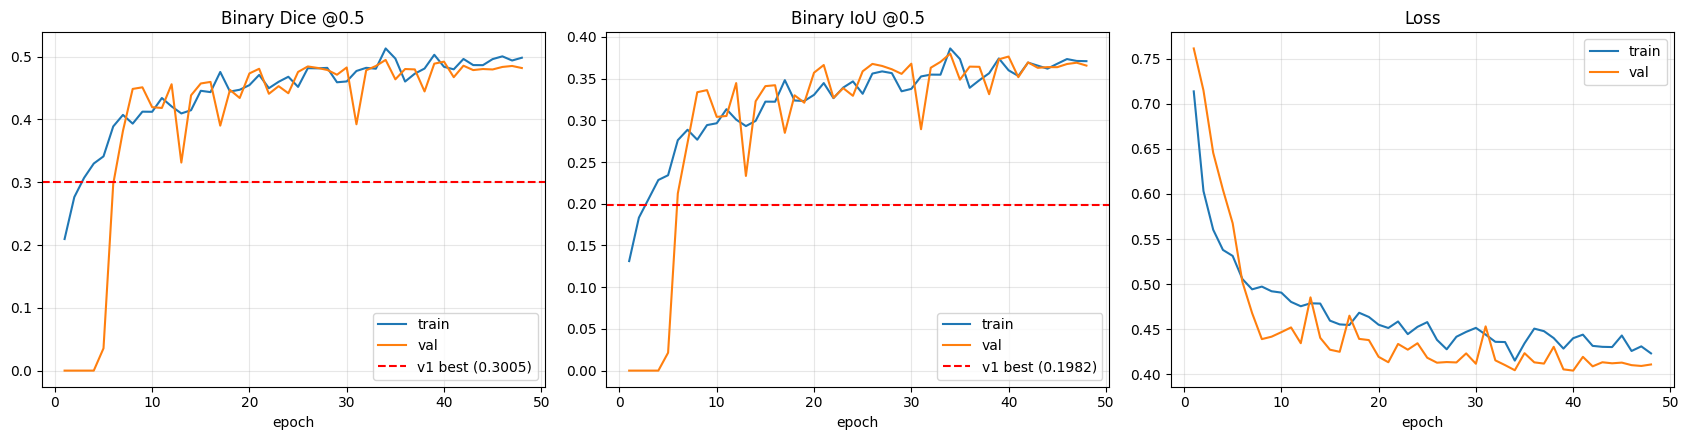

In [25]:
# ============================================================
# 20. CURVES + FIT DIAGNOSIS
# ============================================================
history_df = pd.read_csv(HISTORY_CSV)
history_df["global_epoch"] = np.arange(1, len(history_df) + 1)

assert f"val_{DICE_COL}" in history_df.columns, (
    f"Missing column val_{DICE_COL}. Found: {list(history_df.columns)}"
)

best_idx = int(history_df[f"val_{DICE_COL}"].idxmax())
best_epoch = int(history_df.loc[best_idx, "global_epoch"])
best_dice = float(history_df.loc[best_idx, f"val_{DICE_COL}"])
best_iou = float(history_df.loc[best_idx, f"val_{IOU_COL}"])
gap = float(history_df.loc[best_idx, DICE_COL]) - best_dice

if gap < 0.03:
    verdict = "STILL UNDERFITTING -> raise base_filters / LR"
elif gap > 0.15:
    verdict = "OVERFITTING -> raise dropout / weight decay further"
else:
    verdict = "healthy fit"

print("Best epoch    :", best_epoch, "of", len(history_df))
print("Best val Dice :", f"{best_dice:.4f}   (v1 = {V1_DICE:.4f})")
print("Best val IoU  :", f"{best_iou:.4f}   (v1 = {V1_IOU:.4f})")
print("Improvement   :", f"{(best_dice / V1_DICE - 1) * 100:+.1f}% vs v1")
print("Train-val gap :", f"{gap:+.4f}  ->", verdict)
print("(Note: this reads the CSVLogger history from single-checkpoint training;")
print(" if SWA won in 19b, the final evaluated model differs from 'best_epoch' here")
print(" -- Section 22 reports the number that actually matters.)")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(history_df["global_epoch"], history_df[DICE_COL], label="train")
axes[0].plot(history_df["global_epoch"], history_df[f"val_{DICE_COL}"], label="val")
axes[0].axhline(V1_DICE, ls="--", c="r", label=f"v1 best ({V1_DICE:.4f})")
axes[0].set_title("Binary Dice @0.5")

axes[1].plot(history_df["global_epoch"], history_df[IOU_COL], label="train")
axes[1].plot(history_df["global_epoch"], history_df[f"val_{IOU_COL}"], label="val")
axes[1].axhline(V1_IOU, ls="--", c="r", label=f"v1 best ({V1_IOU:.4f})")
axes[1].set_title("Binary IoU @0.5")

axes[2].plot(history_df["global_epoch"], history_df["loss"], label="train")
axes[2].plot(history_df["global_epoch"], history_df["val_loss"], label="val")
axes[2].set_title("Loss")

for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)

plt.tight_layout()
plt.savefig(RUN_DIR / f"{VARIANT}_curves.png", dpi=140)
plt.show()


Best checkpoint reloaded.


Predicting val:   0%|          | 0/114 [00:00<?, ?it/s]

Validation tensor: (455, 320, 320)
 threshold   dice    iou  precision  recall
    0.1000 0.4682 0.3601     0.3971  0.8917
    0.1500 0.4795 0.3701     0.4209  0.8616
    0.2000 0.4862 0.3757     0.4388  0.8378
    0.2500 0.4905 0.3791     0.4535  0.8167
    0.3000 0.4932 0.3810     0.4662  0.7974
    0.3500 0.4951 0.3823     0.4778  0.7790
    0.4000 0.4961 0.3827     0.4890  0.7604
    0.4500 0.4961 0.3819     0.4998  0.7410
    0.5000 0.4948 0.3799     0.5127  0.7203
    0.5500 0.4928 0.3772     0.5235  0.6987
    0.6000 0.4895 0.3735     0.5347  0.6743
    0.6500 0.4846 0.3683     0.5487  0.6464
    0.7000 0.4775 0.3612     0.5659  0.6129
    0.7500 0.4666 0.3508     0.5866  0.5743
    0.8000 0.4459 0.3309     0.6090  0.5199
    0.8500 0.4061 0.2944     0.6439  0.4390
    0.9000 0.3271 0.2287     0.6976  0.3193

Best threshold : 0.4  Dice: 0.4961


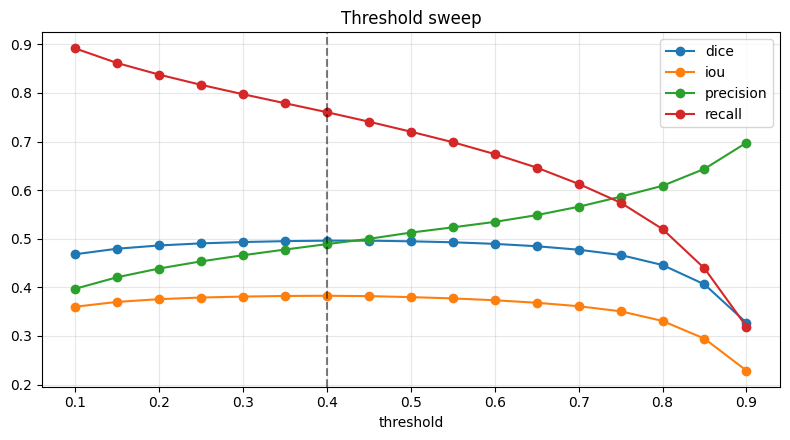

In [26]:
# ============================================================
# 21. THRESHOLD CALIBRATION
#     Reloads BEST_WEIGHTS, which Section 19b overwrites with the SWA
#     average when SWA won -- so this always calibrates against whichever
#     weights are actually going to be shipped.
# ============================================================
model.load_weights(str(BEST_WEIGHTS))
print("Best checkpoint reloaded.")

probs_list, gts_list = [], []
for xb, yb in tqdm(val_ds, desc="Predicting val"):
    out = model.predict(xb, verbose=0)
    pm = out[0] if isinstance(out, (list, tuple)) else out
    probs_list.append(pm[..., 0].astype(np.float32))
    gts_list.append(main_target(yb).numpy()[..., 0].astype(np.float32))

probs = np.concatenate(probs_list, axis=0)
gts = np.concatenate(gts_list, axis=0)
del probs_list, gts_list

assert probs.shape == gts.shape, f"shape mismatch {probs.shape} vs {gts.shape}"
assert len(probs) == len(val_df), (
    f"prediction count {len(probs)} != val rows {len(val_df)}"
)
print("Validation tensor:", probs.shape)


def sweep(probs, gts, thresholds):
    rows = []
    gt_flat = gts.reshape(gts.shape[0], -1)
    gt_sum = gt_flat.sum(1)
    pr_all = probs.reshape(probs.shape[0], -1)
    for t in thresholds:
        pr = (pr_all >= t).astype(np.float32)
        inter = (gt_flat * pr).sum(1)
        pr_sum = pr.sum(1)
        rows.append({
            "threshold": float(t),
            "dice": float(((2 * inter + 1e-6) / (gt_sum + pr_sum + 1e-6)).mean()),
            "iou": float(((inter + 1e-6) / (gt_sum + pr_sum - inter + 1e-6)).mean()),
            "precision": float(((inter + 1e-6) / (pr_sum + 1e-6)).mean()),
            "recall": float(((inter + 1e-6) / (gt_sum + 1e-6)).mean()),
        })
    return pd.DataFrame(rows)


sweep_df = sweep(probs, gts, THRESHOLD_GRID)
sweep_df.to_csv(RUN_DIR / f"{VARIANT}_threshold_sweep.csv", index=False)

best_row = sweep_df.loc[sweep_df["dice"].idxmax()]
BEST_THRESHOLD = float(best_row["threshold"])

print(sweep_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
print("Best threshold :", BEST_THRESHOLD, " Dice:", f"{best_row['dice']:.4f}")

plt.figure(figsize=(8, 4.5))
for col in ("dice", "iou", "precision", "recall"):
    plt.plot(sweep_df["threshold"], sweep_df[col], marker="o", label=col)
plt.axvline(BEST_THRESHOLD, ls="--", c="k", alpha=.5)
plt.xlabel("threshold"); plt.legend(); plt.grid(alpha=.3)
plt.title("Threshold sweep")
plt.tight_layout()
plt.savefig(RUN_DIR / f"{VARIANT}_threshold_sweep.png", dpi=140)
plt.show()


In [27]:
# ============================================================
# 22. FINAL EVAL + LESION-SIZE BREAKDOWN
# ============================================================
pred_bin = (probs >= BEST_THRESHOLD).astype(np.float32)
gt_flat = gts.reshape(gts.shape[0], -1)
pr_flat = pred_bin.reshape(pred_bin.shape[0], -1)

inter = (gt_flat * pr_flat).sum(1)
dice_per_image = (2 * inter + 1e-6) / (gt_flat.sum(1) + pr_flat.sum(1) + 1e-6)
iou_per_image = (inter + 1e-6) / (gt_flat.sum(1) + pr_flat.sum(1) - inter + 1e-6)

final_dice = float(dice_per_image.mean())
final_iou = float(iou_per_image.mean())

print("=" * 60)
print("FINAL VALIDATION --", VARIANT)
print("=" * 60)
print(f"Threshold        : {BEST_THRESHOLD}")
print(f"Dice             : {final_dice:.4f}   (v1: {V1_DICE:.4f})")
print(f"IoU              : {final_iou:.4f}   (v1: {V1_IOU:.4f})")
print(f"Dice std         : {float(dice_per_image.std()):.4f}")
print(f"Images Dice>0.5  : {int((dice_per_image > 0.5).sum())} / {len(dice_per_image)}")
print(f"Images Dice<0.1  : {int((dice_per_image < 0.1).sum())} / {len(dice_per_image)}")

size_df = val_df.copy()
size_df["dice"] = dice_per_image
size_df["iou"] = iou_per_image
size_df["size_bin"] = pd.cut(size_df["lesion_frac"],
                             bins=SIZE_BIN_EDGES, labels=SIZE_BIN_LABELS)

breakdown = size_df.groupby("size_bin", observed=True).agg(
    images=("dice", "size"), mean_dice=("dice", "mean"), mean_iou=("iou", "mean")
).round(4)

print()
print("Performance by lesion size (compare against the previous run's table:")
print("  <1%: 0.248 | 1-5%: 0.466 | 5-15%: 0.664 | >15%: 0.781):")
print(breakdown.to_string())
breakdown.to_csv(RUN_DIR / f"{VARIANT}_size_breakdown.csv")


FINAL VALIDATION -- mu_b_tuned
Threshold        : 0.4
Dice             : 0.4961   (v1: 0.3005)
IoU              : 0.3827   (v1: 0.1982)
Dice std         : 0.2936
Images Dice>0.5  : 228 / 455
Images Dice<0.1  : 59 / 455

Performance by lesion size (compare against the previous run's table:
  <1%: 0.248 | 1-5%: 0.466 | 5-15%: 0.664 | >15%: 0.781):
          images  mean_dice  mean_iou
size_bin                             
<1%           59     0.0958    0.0535
1-5%         136     0.3257    0.2110
5-15%        122     0.6086    0.4725
>15%         138     0.7358    0.6132


In [28]:
# ============================================================
# 23. SAVE ARTIFACTS + MODEL-SIZE COMPARISON
# ============================================================
model.save(str(FINAL_MODEL))
model.save_weights(str(FINAL_WEIGHTS))

with open(RUN_DIR / f"{VARIANT}_architecture.json", "w") as f:
    f.write(model.to_json())

on_disk_mb = FINAL_MODEL.stat().st_size / (1024 ** 2)
weights_mb = FINAL_WEIGHTS.stat().st_size / (1024 ** 2)

with open(RUN_DIR / f"{VARIANT}_inference_config.json", "w") as f:
    json.dump({
        "variant": VARIANT, "family": "Mobile-UNet",
        "img_size": IMG_SIZE, "letterbox": LETTERBOX_RESIZE,
        "input_range": "[0,255] float32 (model rescales internally)",
        "best_threshold": BEST_THRESHOLD,
        "val_dice": final_dice, "val_iou": final_iou,
        "total_params": total_params, "fp32_mb": round(fp32_mb, 2),
        "keras_file_mb": round(on_disk_mb, 2),
        "used_swa": bool(swa_model is not None and swa_dice > best_dice_single)
                    if swa_model is not None else False,
    }, f, indent=2)

summary = {
    "variant": VARIANT,
    "family": "Mobile-UNet",
    "base_filters": BASE_FILTERS,
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "grad_accum_steps": GRAD_ACCUM_STEPS,
    "effective_batch": EFFECTIVE_BATCH,
    "residual": USE_RESIDUAL,
    "gates": USE_GATES,
    "cbam": USE_CBAM,
    "aspp": USE_ASPP,
    "deep_sup": USE_DEEP_SUP,
    "optimizer": f"AdamW cosine lr={BASE_LR} wd={WEIGHT_DECAY}",
    "loss": "0.5*BCE + 0.5*FocalTversky(0.3,0.7)",
    "total_params": total_params,
    "trainable_params": trainable_params,
    "fp32_mb": round(fp32_mb, 2),
    "keras_file_mb": round(on_disk_mb, 2),
    "weights_file_mb": round(weights_mb, 2),
    "epochs_run": len(history_df),
    "best_epoch": best_epoch,
    "best_threshold": BEST_THRESHOLD,
    "val_dice": round(final_dice, 4),
    "val_iou": round(final_iou, 4),
    "train_val_gap": round(gap, 4),
    "training_minutes": round(training_seconds / 60.0, 2),
}

pd.DataFrame([summary]).to_csv(RUN_DIR / f"{VARIANT}_summary.csv", index=False)

V1_ROW = {
    "variant": "v1_original", "family": "Mobile-UNet", "base_filters": 16,
    "img_size": 256, "batch_size": 16, "grad_accum_steps": 1, "effective_batch": 16,
    "residual": False, "gates": False,
    "cbam": True, "aspp": False, "deep_sup": False,
    "optimizer": "SGD+Nesterov 1e-4 -> 5e-5", "loss": "BCE + Dice",
    "total_params": V1_PARAMS, "trainable_params": 308375,
    "fp32_mb": round(V1_PARAMS * 4 / 1024 ** 2, 2),
    "keras_file_mb": np.nan, "weights_file_mb": np.nan,
    "epochs_run": 55, "best_epoch": 55, "best_threshold": 0.5,
    "val_dice": round(V1_DICE, 4), "val_iou": round(V1_IOU, 4),
    "train_val_gap": 0.0093, "training_minutes": 236.43,
}

PREV_ROW = {
    "variant": "mu_b_tuned_v1revision (prior notebook)", "family": "Mobile-UNet",
    "base_filters": 32, "img_size": 256, "batch_size": 6, "grad_accum_steps": 1,
    "effective_batch": 6, "residual": True, "gates": True, "cbam": True, "aspp": False,
    "deep_sup": False, "optimizer": "AdamW cosine lr=3e-4 wd=1e-5",
    "loss": "0.5*BCE + 0.5*FocalTversky(0.3,0.7)",
    "total_params": 1_550_000, "trainable_params": np.nan,
    "fp32_mb": round(1_550_000 * 4 / 1024 ** 2, 2),
    "keras_file_mb": np.nan, "weights_file_mb": np.nan,
    "epochs_run": 50, "best_epoch": 20, "best_threshold": 0.5,
    "val_dice": 0.586, "val_iou": np.nan,
    "train_val_gap": 0.12, "training_minutes": np.nan,
}

if COMPARE_CSV.exists():
    comp = pd.read_csv(COMPARE_CSV)
    comp = comp[comp["variant"] != VARIANT]
    comp = pd.concat([comp, pd.DataFrame([summary])], ignore_index=True)
    if "v1_original" not in set(comp["variant"]):
        comp = pd.concat([pd.DataFrame([V1_ROW]), comp], ignore_index=True)
    if "mu_b_tuned_v1revision (prior notebook)" not in set(comp["variant"]):
        comp = pd.concat([pd.DataFrame([PREV_ROW]), comp], ignore_index=True)
else:
    comp = pd.DataFrame([V1_ROW, PREV_ROW, summary])

comp = comp.sort_values("total_params").reset_index(drop=True)
comp.to_csv(COMPARE_CSV, index=False)

print("Saved:", FINAL_MODEL, f"({on_disk_mb:.2f} MB on disk)")
print()
print("=" * 104)
print("MOBILE-UNET SIZE vs ACCURACY COMPARISON")
print("=" * 104)
print(comp[["variant", "base_filters", "img_size", "total_params", "fp32_mb",
            "keras_file_mb", "best_epoch", "best_threshold",
            "val_dice", "val_iou", "training_minutes"]]
      .to_string(index=False))
print()
print("Efficiency (Dice per 100k params):")
for _, r in comp.iterrows():
    if pd.notna(r["val_dice"]) and pd.notna(r["total_params"]) and r["total_params"] > 0:
        eff = r["val_dice"] / (r["total_params"] / 1e5)
        print(f"  {r['variant']:<38}{eff:>8.4f}")


Saved: /kaggle/working/Segmentation Output/lesion_mu_b_tuned/mu_b_tuned_final.keras (24.16 MB on disk)

MOBILE-UNET SIZE vs ACCURACY COMPARISON
                               variant  base_filters  img_size  total_params  fp32_mb  keras_file_mb  best_epoch  best_threshold  val_dice  val_iou  training_minutes
                           v1_original            16       256        311319     1.19            NaN          55             0.5    0.3005   0.1982            236.43
mu_b_tuned_v1revision (prior notebook)            32       256       1550000     5.91            NaN          20             0.5    0.5860      NaN               NaN
                            mu_b_tuned            32       320       1552563     5.92          24.16          34             0.4    0.4961   0.3827             59.15

Efficiency (Dice per 100k params):
  v1_original                             0.0965
  mu_b_tuned_v1revision (prior notebook)  0.0378
  mu_b_tuned                              0.0320


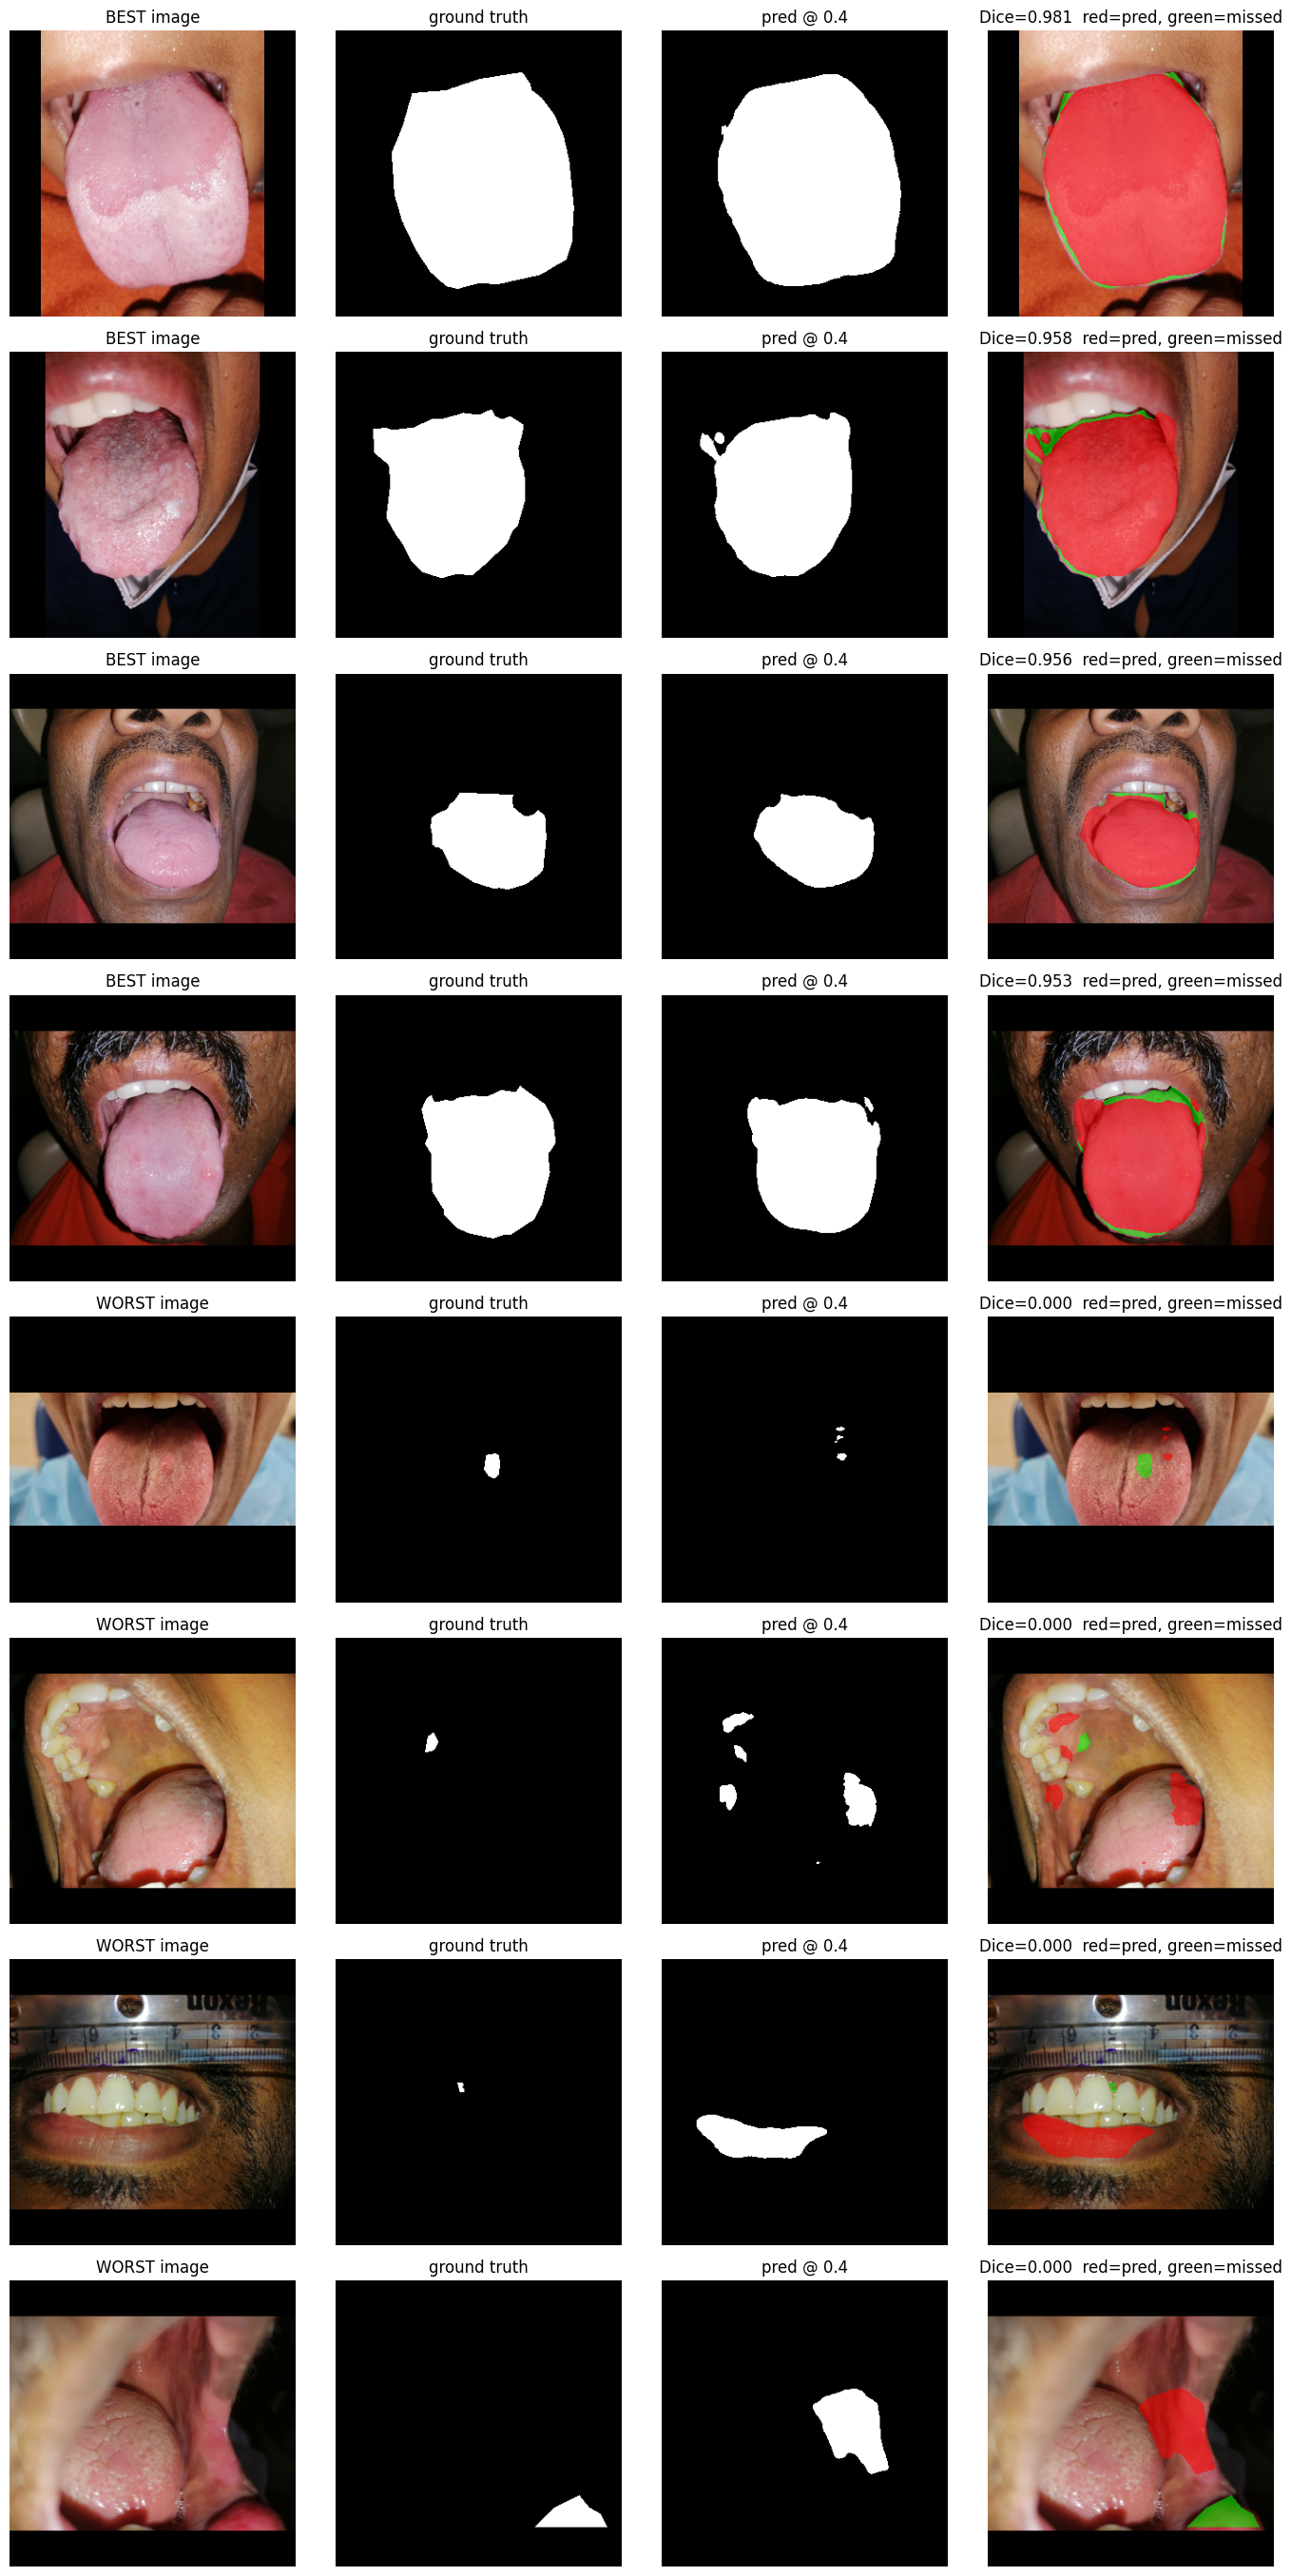

In [29]:
# ============================================================
# 24. QUALITATIVE PREDICTIONS (4 best + 4 worst)
# ============================================================
SEG_DIR = RUN_DIR / "final_segmented"
SEG_DIR.mkdir(parents=True, exist_ok=True)

order = np.argsort(-dice_per_image)
show_idx = list(order[:4]) + list(order[-4:])

fig, axes = plt.subplots(len(show_idx), 4, figsize=(14, 3.4 * len(show_idx)))

for r, idx in enumerate(show_idx):
    idx = int(idx)
    row = val_df.iloc[idx]

    img = safe_imread(row["image_path"], cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = (letterbox(img, IMG_SIZE, cv2.INTER_AREA) if LETTERBOX_RESIZE
           else cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))

    gt = (gts[idx] * 255).astype(np.uint8)
    pm = (pred_bin[idx] * 255).astype(np.uint8)

    ov = img.copy()
    hit = pm > 0
    miss = (gt > 0) & (pm == 0)
    ov[hit] = (0.45 * ov[hit] + 0.55 * np.array([255, 0, 0])).astype(np.uint8)
    ov[miss] = (0.45 * ov[miss] + 0.55 * np.array([0, 255, 0])).astype(np.uint8)

    tag = "BEST" if r < 4 else "WORST"
    axes[r, 0].imshow(img);             axes[r, 0].set_title(f"{tag} image")
    axes[r, 1].imshow(gt, cmap="gray"); axes[r, 1].set_title("ground truth")
    axes[r, 2].imshow(pm, cmap="gray"); axes[r, 2].set_title(f"pred @ {BEST_THRESHOLD}")
    axes[r, 3].imshow(ov)
    axes[r, 3].set_title(f"Dice={dice_per_image[idx]:.3f}  red=pred, green=missed")
    for c in range(4):
        axes[r, c].axis("off")

    cv2.imwrite(str(SEG_DIR / f"{row['image_id']}_pred.png"),
                cv2.cvtColor(ov, cv2.COLOR_RGB2BGR))

plt.tight_layout()
plt.savefig(RUN_DIR / f"{VARIANT}_predictions.png", dpi=140)
plt.show()


In [30]:
# ============================================================
# 25. FINAL AUDIT
# ============================================================
required = [
    BEST_WEIGHTS, FINAL_MODEL, FINAL_WEIGHTS, HISTORY_CSV,
    RUN_DIR / f"{VARIANT}_summary.csv",
    RUN_DIR / f"{VARIANT}_architecture.json",
    RUN_DIR / f"{VARIANT}_inference_config.json",
    RUN_DIR / f"{VARIANT}_threshold_sweep.csv",
    RUN_DIR / f"{VARIANT}_size_breakdown.csv",
    RUN_DIR / f"{VARIANT}_curves.png",
    RUN_DIR / f"{VARIANT}_predictions.png",
    RUN_DIR / "jpeg_integrity_scan.csv",
]
missing = [str(p) for p in required if not p.exists()]
print("Missing artifacts:", missing if missing else "none")
assert not missing, "STOP: artifacts missing."

print()
print("Audit")
print("  Architecture family    : Mobile-UNet (depthwise separable) ONLY")
print("  External backbone      : NONE")
print("  Pretrained weights     : NONE")
print("  Transfer learning      : NONE")
print("  Variant                :", VARIANT)
print("  Base filters           :", BASE_FILTERS, "(unchanged from prior revision)")
print("  Image size             :", IMG_SIZE, "(was 256)")
print("  Effective batch        :", EFFECTIVE_BATCH, "via grad_accum_steps =", GRAD_ACCUM_STEPS)
print("  Lesion-centered crop    :", TRAIN_CROP_PROB, "probability")
print("  Size-bin oversampling  :", OVERSAMPLE_SMALL_LESIONS, SIZE_BIN_TARGET_FREQ)
print("  Elastic / cutout aug    :", ELASTIC_PROB, "/", CUTOUT_PROB)
print("  Weight decay            :", WEIGHT_DECAY, "(was 1e-5)")
print("  SWA applied             :", bool(swa_model is not None and swa_dice > best_dice_single)
      if swa_model is not None else False)
print("  Residual sep blocks    :", USE_RESIDUAL)
print("  Attention gates        :", USE_GATES)
print("  CBAM bottleneck        :", USE_CBAM)
print("  ASPP bottleneck        :", USE_ASPP)
print("  Deep supervision       :", USE_DEEP_SUP)
print("  Layer-name registry    : ACTIVE (duplicate names impossible)")
print("  All variants build-test:", "PASSED before training" if RUN_VARIANT_SELF_TEST else "skipped (preflight still ran)")
print("  Optimizer              : AdamW warmup+cosine (no ReduceLROnPlateau)")
print("  Loss                   : 0.5*BCE + 0.5*FocalTversky(0.3, 0.7)")
print("  Custom objects         : registered (save/load safe)")
print("  Resize                 :", "letterbox" if LETTERBOX_RESIZE else "square squash")
print("  Split                  : stratified by lesion area, leak-checked")
print("  Threshold              : calibrated ->", BEST_THRESHOLD)
print("  Epoch budget           :", TOTAL_EPOCHS)
print()
print(f"  SIZE    : {total_params:,} params, {fp32_mb:.2f} MB FP32, {on_disk_mb:.2f} MB on disk")
print(f"  RESULT  : val Dice {final_dice:.4f}  val IoU {final_iou:.4f}"
      f"  (prior notebook's best: 0.586 Dice)")
print()
print("Size breakdown this run (compare against 0.248 / 0.466 / 0.664 / 0.781 previously):")
print(breakdown.to_string())


Missing artifacts: none

Audit
  Architecture family    : Mobile-UNet (depthwise separable) ONLY
  External backbone      : NONE
  Pretrained weights     : NONE
  Transfer learning      : NONE
  Variant                : mu_b_tuned
  Base filters           : 32 (unchanged from prior revision)
  Image size             : 320 (was 256)
  Effective batch        : 16 via grad_accum_steps = 4
  Lesion-centered crop    : 0.7 probability
  Size-bin oversampling  : True {'<1%': 0.35, '1-5%': 0.3, '5-15%': 0.2, '>15%': 0.15}
  Elastic / cutout aug    : 0.3 / 0.3
  Weight decay            : 5e-05 (was 1e-5)
  SWA applied             : False
  Residual sep blocks    : True
  Attention gates        : True
  CBAM bottleneck        : True
  ASPP bottleneck        : False
  Deep supervision       : False
  Layer-name registry    : ACTIVE (duplicate names impossible)
  All variants build-test: skipped (preflight still ran)
  Optimizer              : AdamW warmup+cosine (no ReduceLROnPlateau)
  Loss     

## Ensembling trained variants

Run this cell after you have trained more than one variant (each in its own kernel
session, per the instructions at the bottom). It loads every `*_final.keras` it can find
under `OUTPUT_ROOT`, averages their sigmoid probability maps on the validation set, and
reports whether the ensemble beats the best single variant. This costs nothing extra to
train -- it only helps if you already have >= 2 saved models, and it needs each variant's
own `IMG_SIZE` to preprocess correctly, which is why it re-derives images per model rather
than reusing the `val_ds` built earlier in this session (that dataset was built at only
one variant's IMG_SIZE).


In [31]:
# ============================================================
# 26. MULTI-VARIANT ENSEMBLE AT INFERENCE (NEW)
# ============================================================
custom_objects = {
    "CBAM": CBAM, "WarmupCosine": WarmupCosine, "combined_loss": combined_loss,
    "dice_coef": dice_coef, "iou_coef": iou_coef, "bin_dice": bin_dice, "bin_iou": bin_iou,
}

found_models = {}
for v in ENSEMBLE_VARIANTS:
    p = OUTPUT_ROOT / f"lesion_{v}" / f"{v}_final.keras"
    if p.exists():
        found_models[v] = p

print("Found trained variants for ensembling:", list(found_models.keys()))

if len(found_models) < 2:
    print("Fewer than 2 variants trained so far in", OUTPUT_ROOT,
          "-- train at least one more variant (change VARIANT in Section 2, "
          "restart kernel, rerun) before this cell can do anything useful.")
else:
    # Use this session's own val_df (image ids / split) as the common
    # evaluation set -- every variant was trained against the SAME
    # stratified split (fixed SEED), so val_df here is identical across
    # sessions as long as INCLUDE_NEGATIVES / VAL_FRACTION weren't changed.
    ensemble_probs = {}
    for v, path in found_models.items():
        print(f"Loading {v} ...")
        m = tf.keras.models.load_model(str(path), custom_objects=custom_objects,
                                       compile=False)
        v_img_size = VARIANTS[v]["img_size"]

        preds = []
        for _, row in tqdm(val_df.iterrows(), total=len(val_df), desc=f"predict[{v}]"):
            img = safe_imread(row["image_path"], cv2.IMREAD_COLOR)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = letterbox(img, v_img_size, cv2.INTER_AREA) if LETTERBOX_RESIZE \
                  else cv2.resize(img, (v_img_size, v_img_size), interpolation=cv2.INTER_AREA)
            out = m.predict(img[None].astype(np.float32), verbose=0)
            pm = out[0] if isinstance(out, (list, tuple)) else out
            pm = pm[0, ..., 0]
            if v_img_size != IMG_SIZE:
                pm = cv2.resize(pm, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
            preds.append(pm)
        ensemble_probs[v] = np.stack(preds, axis=0)
        del m
        tf.keras.backend.clear_session()

    # Ground truth at the ensemble's common IMG_SIZE
    ens_gts = []
    for _, row in val_df.iterrows():
        mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
        mask = letterbox(mask, IMG_SIZE, cv2.INTER_NEAREST) if LETTERBOX_RESIZE \
               else cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
        ens_gts.append((mask > 127).astype(np.float32))
    ens_gts = np.stack(ens_gts, axis=0)

    def _dice_at(probs_avg, gt, thresh):
        pr = (probs_avg >= thresh).astype(np.float32)
        gt_flat = gt.reshape(gt.shape[0], -1)
        pr_flat = pr.reshape(pr.shape[0], -1)
        inter = (gt_flat * pr_flat).sum(1)
        return float(((2 * inter + 1e-6) /
                      (gt_flat.sum(1) + pr_flat.sum(1) + 1e-6)).mean())

    print()
    print("Per-variant Dice @ 0.5 on this common comparison set:")
    for v, p in ensemble_probs.items():
        print(f"  {v:<18}{_dice_at(p, ens_gts, 0.5):.4f}")

    stacked = np.stack(list(ensemble_probs.values()), axis=0)
    avg_probs = stacked.mean(axis=0)

    best_single_dice = max(_dice_at(p, ens_gts, 0.5) for p in ensemble_probs.values())
    best_ens_thresh, best_ens_dice = 0.5, -1.0
    for t in THRESHOLD_GRID:
        d = _dice_at(avg_probs, ens_gts, float(t))
        if d > best_ens_dice:
            best_ens_dice, best_ens_thresh = d, float(t)

    print()
    print(f"Best single variant Dice : {best_single_dice:.4f}")
    print(f"Ensemble ({len(ensemble_probs)}-way avg) Dice : {best_ens_dice:.4f}"
          f"  @ threshold {best_ens_thresh}")
    print("Ensemble helps" if best_ens_dice > best_single_dice else
          "Ensemble did not beat the best single variant on this split")

    np.save(OUTPUT_ROOT / "ensemble_avg_probs.npy", avg_probs)
    pd.DataFrame([{
        "variants": ",".join(ensemble_probs.keys()),
        "best_single_dice": best_single_dice,
        "ensemble_dice": best_ens_dice,
        "ensemble_threshold": best_ens_thresh,
    }]).to_csv(OUTPUT_ROOT / "ensemble_summary.csv", index=False)
    print("Saved:", OUTPUT_ROOT / "ensemble_summary.csv")


Found trained variants for ensembling: ['mu_b_tuned']
Fewer than 2 variants trained so far in /kaggle/working/Segmentation Output -- train at least one more variant (change VARIANT in Section 2, restart kernel, rerun) before this cell can do anything useful.


## Running the other variants

1. Change `VARIANT` in Section 2.
2. Restart the kernel.
3. Run all cells — masks, the dataset index, and the JPEG scan are cached, so only
   training re-runs.
4. Every run appends to `mobileunet_variant_comparison.csv` with params, FP32 MB,
   on-disk MB, Dice, IoU, and Dice-per-100k-params efficiency (Section 23).
5. Once at least two variants are trained, rerun Section 26 to check whether
   ensembling them beats your best single model.

Order: `mu_a_ablation` → `mu_b_tuned` → `mu_c_wide_aspp` → `mu_d_deepsup`.

Section 20 prints a fit verdict. If it says **STILL UNDERFITTING**, raise `base_filters`
in the `VARIANTS` dict for that variant. If it still says **OVERFITTING** after this
revision, raise `WEIGHT_DECAY` and `DROPOUT` further in Section 2 before touching
capacity again — this revision already moved weight decay from 1e-5 to 5e-5 and dropout
up by ~0.05 across variants specifically because the prior run's gap was 0.12.

If the **size-breakdown table** (Section 22) still shows `<1%` and `1-5%` lagging badly
behind `>15%` after this run, the next lever is `TRAIN_CROP_PROB` and
`SIZE_BIN_TARGET_FREQ` in Section 2 — push both further toward small lesions before
adding any more augmentation or capacity.
